---
title: "Geldart's powder groups: the boundaries, and what his own table says about them"
description: "Geldart's 1973 classification is not a differential equation: it is two inequalities and a map. This page recomputes both boundary constants from the expressions he printed, tests the A/B boundary row by row against the size fractions he measured, measures what the minimum-fluidization correlation underneath it is worth against those same measurements, and shows that the B/D boundary is the Davidson cloud-existence condition written in other symbols."
categories: [sec:A, struct:S3, tier:T0, data:tier2, phase:gas-solid]
date: 2026-08-02
---

# Geldart's powder groups: the boundaries, and what his own table says about them

**Catalog ID:** `A1.7` · **Structures:** `S3` (the one pymrm solve on the page) · **Tier:** T0 · **Data tier:** 2 (a printed table of the author's own measurements)

Ask which fluidised-bed model applies to a powder and the first answer anyone
gives is a letter. **A** expands smoothly before it bubbles; **B** bubbles the
moment it fluidises; **C** will not fluidise at all; **D** spouts. The letters
come from one seven-page paper, and the thing the paper actually contributes is
not the letters but **two inequalities**:

$$(\rho_s-\rho_f)\,d' \le 225 \quad\text{(group A)},\qquad
  (\rho_s-\rho_f)\,(d')^2 \ge 10^6 \quad\text{(group D)},$$

with $\rho$ in g cm$^{-3}$ and $d'$ the mean particle size in µm.

Those two numbers are quantitative predictions, so they can be checked. This
page does four things with them and does not pretend to do a fifth:

1. **Recomputes 225 and $10^6$** from the expressions Geldart derives them from,
   using his own $g$, $\mu$, $K_{MB}$, $\varepsilon_0$ and $d_B$. Neither comes
   back exact.
2. **Tests the A/B boundary against the size fractions Geldart measured
   himself.** The boundary uses only size and density; the verdict it is tested
   against uses only the two measured velocity columns. The two routes share no
   input column (one residual link, through the fit that supplies the 100 inside
   the 225, is named and measured in the validation section). Almost every
   fraction in the table is group A, so a whole-table score is nearly free: the
   page prints a **null baseline** beside it, names the handful of rows on
   which the criterion can possibly beat that baseline, and quotes its score on
   those rows as the result.
3. **Measures the minimum-fluidization correlation that the boundary is built
   on**, equation (3), which is Davies and Richardson's and was not fitted to
   these data, against the measured $U_0$ column. This is the weakest link in
   the boundary and the paper never quantifies it.
4. **Shows that the B/D boundary is a cloud-existence condition.** Geldart's
   equation (7) is, term for term, the statement that a 25 cm bubble rises more
   slowly than the interstitial gas, which is exactly the threshold the
   [`E1.2`](../E1.2-davidson-bubble/) page derives for the Davidson bubble to
   have no cloud at all. The two differ by the coefficient $1/\sqrt2$ against
   $0.711$, which is less than the rounding Geldart applied to his own answer.

**What this page does not do:** it does not reproduce the C/A boundary. Geldart
prints no expression for it (on his Figure 3 it is a shaded band drawn by hand
to separate the powders other authors called difficult from the ones they called
group A) and nothing here is digitised from any figure.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.10.3"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A1.7-geldart-classification"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Packages beyond pymrm and the Colab defaults (numpy, scipy, pandas,
# matplotlib, pyyaml) are installed here with subprocess, not %pip. pymrm is used
# only through model.py (the Davidson bubble of E1.2, copied unchanged).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from gallery_utils import Claims, cite_data, load_claims, load_data, load_meta
from model import DavidsonBubble, cloud_radius_exact, rise_velocity

PAGE_E12 = "E1.2-davidson-bubble"          # owns the Davidson bubble and its model.py
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
claims = Claims(PAGE.split("-")[0])
BREAK = []   # (injected defect, claim, clean value, broken value, caught)


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught


def brk_all(row, got):
    """Break row for every claim of a group: ``got`` maps claim names to the values the
    helper returns when it is called with the defect injected."""
    return {name: brk(row, name, v) for name, v in got.items() if name in claims.metrics}


def fill(text, **kw):
    """Put computed numbers into prose: ``@@name@@`` is replaced by ``kw['name']``."""
    for k, v in kw.items():
        text = text.replace(f"@@{k}@@", str(v))
    assert "@@" not in text, "unfilled placeholder"
    return text


def say(text, **kw):
    display(Markdown(fill(text, **kw)))

## Background

Before 1973 the fluidisation literature was in the habit of generalising from
one powder. Geldart's opening complaint is exactly that: conclusions drawn from
cracking catalyst were being applied to powders of quite different size and
density, and this "is responsible for some of the apparent contradictions and
differences of opinion which appear in published papers."

His fix was to sort powders into four groups by two properties only (the
density difference $\rho_s-\rho_f$ and the mean size $d_{sv}$) and then to be
strict about what may be carried across a group boundary. The summary is blunt
about the limit of its own usefulness:

> Generalizations concerning powders within a group can be made with reasonable
> confidence but conclusions drawn from observations made on a powder in one
> group should not in general be used to predict the behaviour of a powder in
> another group.

The four groups, in his words (section 3, journal pages 286–287):

| group | behaviour |
|---|---|
| **A** | beds "expand considerably before bubbling commences"; collapse slowly, typically 0.3–0.6 cm/s; gross powder circulation even with few bubbles; bubbles split and recoalesce; a maximum bubble size exists |
| **B** | "bubbles start to form ... at or only slightly above minimum fluidization velocity"; bed expansion small, collapse rapid; bubble size grows linearly with height and with $U-U_0$; no evidence of a maximum bubble size |
| **C** | "powders which are in any way cohesive"; lift as a plug or channel badly, because interparticle forces exceed what the fluid can exert; fixed by stirrers, vibration, fumed silica, or making the walls conducting |
| **D** | large and/or very dense; "all but the largest bubbles rise more slowly than the interstitial fluidizing gas, so that gas flows into the base of the bubble and out of the top"; can be made to spout |

Group D's definition is the one that matters later on this page: it is a
statement about a **bubble rising more slowly than the gas around it**, which is
the same object the [`E1.2`](../E1.2-davidson-bubble/) page solves for.

The classification is a `T0` case because it is upstream of everything else in
section E. Which of the gallery's fluidised-bed pages applies to a given powder
is, in practice, decided by its Geldart group: `E2.1`'s bubbling-bed model
presumes bubbles and a cloud, and `E1.2`'s cloud has a threshold below which it
does not exist. What this page adds to that chain is the arithmetic that says
which side of the threshold a powder is on.

## The published model

### Provenance

Everything below was read from **Geldart, D., "Types of gas fluidization",
*Powder Technology* **7**(5) 285–292 (1973)**, doi
[10.1016/0032-5910(73)80037-3](https://doi.org/10.1016/0032-5910(73)80037-3),
on 600 dpi renders of journal pages 285–292. The paper itself was read, not a
reprint of it.

The text layer of this Elsevier scan is not usable (it renders the paper's own
title as "Types of Gas Fhidization"), so **every equation, constant and table
value here was read visually off the rendered page image**, and nothing was
repaired by inference. Two places where the print is degraded are recorded as
judgements rather than silently fixed: the exponent in equation (7) is a
half-power, and the heading of Table 1's fifth column is $U_{MB}$ (the printed
subscript is damaged and scans as "MP"). Both are settled by the surrounding
text, and neither is a digit.

**One result on this page originates elsewhere.** Equation (3), the minimum
fluidization velocity, carries Geldart's reference 11: *L. Davies and J. F.
Richardson, Trans. Inst. Chem. Engrs., 44 (1966) T293*. That paper is **not on
disk and was not consulted**; equation (3) is used here exactly as Geldart
prints it, and every statement about "the correlation" is a statement about the
form printed on journal page 289. The same applies to equation (9)
(Verloop and Heertjes, ref. 10) and equation (10) (Oltrogge, ref. 36).

### The equations, as printed

The nomenclature is Geldart's own list of symbols, journal page 291: $g = 981$
cm s$^{-2}$; $d_{sv}$ the surface/volume diameter in **cm**; $d'$ the particle
size in **µm** ($=$ cm $\times 10^4$); $d_B$ the frontal diameter of a bubble in
cm; $U_0$ the superficial velocity at minimum fluidization, cm s$^{-1}$;
$U_{MB}$ the superficial velocity at minimum bubbling, cm s$^{-1}$;
$\varepsilon_0$ the bed voidage at minimum fluidization; $\mu$ the gas viscosity
in g cm$^{-1}$ s$^{-1}$; $\rho_f$, $\rho_s$ gas and particle density, g cm$^{-3}$.

**The bubble point** (journal page 288, from Figure 1):

$$U_{MB} = K_{MB}\,d_{sv} \tag{1}$$

$$U_{MB} = 100\,d_{sv} \tag{2}$$

$K_{MB}$ "has a value of 100 when $U_{MB}$ is in cm s$^{-1}$ and $d_{sv}$ in
cm". Geldart notes it is "curious that the bubble point can be correlated by
means of an equation which involves a term ($K_{MB}$) having units of
frequency", considers Hiby's 7–25 s$^{-1}$ bed oscillation as an explanation and
rejects it because 100 is much larger.

**Minimum fluidization** (journal page 289, his reference 11):

$$U_0 = \frac{8\times10^{-4}\,g\,d_{sv}^2\,(\rho_s-\rho_f)}{\mu} \tag{3}$$

**The A/B criterion** (journal page 289). A powder is group A when the bed
bubbles later than it fluidises:

$$\frac{U_{MB}}{U_0} \ge 1 \tag{4}$$

Substituting (1) and (3) into (4):

$$\frac{8\times10^{-4}\,g\,d_{sv}\,(\rho_s-\rho_f)}{K_{MB}\,\mu} \le 1 \tag{5}$$

and then, "for air at room temperature and pressure $K_{MB} = 100$ and
$\mu = 1.8\times10^{-4}$ poise", replacing $d_{sv}$ (cm) by $d'$ (µm):

$$(\rho_s-\rho_f)\,d' \le 225 \tag{6}$$

This is the line **XY** on his Figure 3.

**The B/D criterion** (journal pages 289–290). The density/size combinations
for which bubbles smaller than $d_B$ "would rise more slowly than the
interstitial gas velocity":

$$\left(g\,\frac{d_B}{2}\right)^{\tfrac12} \le
  \frac{8\times10^{-4}(\rho_s-\rho_f)\,g\,d_{sv}^2}{\mu\,\varepsilon_0} \tag{7}$$

with, for group D, "$d_B = 25$ cm. The choice is not critical since in eqn. (7)
we are considering $\sqrt{d_B}$. For large-particle systems $\varepsilon_0
\approx 0.4$ and for air $\mu = 1.8\times10^{-4}$ g cm$^{-1}$ s$^{-1}$":

$$(\rho_s-\rho_f)(d')^2 \ge 10^6 \tag{8}$$

Geldart calls this criterion "tentative" and says the use of (3) on the
right-hand side of (7) "is not strictly justified for these large particles
since the flow regime is transitional, not laminar."

**Two competing criteria**, for comparison (journal page 291). Verloop and
Heertjes (ref. 10), and Oltrogge (ref. 36), predict immediate bubbling when

$$\frac{(g\,d^3)^{\frac12}(\rho_s-\rho_f)}{\mu} > 5000 \tag{9}$$

$$\frac{(g\,d^3)^{\frac12}(\rho_s-\rho_f)}{\mu} > 400 \tag{10}$$

Geldart states that (9) "lies much too far to the right and is not shown on
Fig. 3", while (10) is drawn there as line O–O and "agrees with published
results about as well as eqn. (5)". Section [Validation](#validation) checks both
statements against the transcribed equations.

## Parameters and assumptions

Everything on this page runs in the paper's own CGS units, because every printed
constant ($8\times10^{-4}$, $K_{MB} = 100$, 225, $10^6$) is dimensional and
carries them.

| symbol | value | where it comes from |
|---|---|---|
| $g$ | 981 cm s$^{-2}$ | list of symbols, journal page 291 |
| $\mu$ | $1.8\times10^{-4}$ g cm$^{-1}$ s$^{-1}$ | stated twice, journal pages 289 and 290, "for air" |
| $\rho_f$ | $1.2\times10^{-3}$ g cm$^{-3}$ | **not printed in this paper.** Air at ambient. See below. |
| $K_{MB}$ | 100 s$^{-1}$ | equation (2), journal page 288 |
| $\varepsilon_0$ | 0.4 | journal page 290, "for large-particle systems" |
| $d_B$ | 25 cm | journal page 290, "bubble sizes greater than 25 cm have rarely been reported" |
| $c_{ubr}$ | 0.711 | the Davies–Taylor coefficient of the bubble rise velocity $0.711\sqrt{g\,d_b}$; **not printed by Geldart**, taken from `E1.2` where it is likewise taken as given |

**The one number not printed in the paper is $\rho_f$**, and it does not matter.
Geldart writes every criterion in terms of $\rho_s-\rho_f$ and never says what he
takes $\rho_f$ to be; for air at ambient it is about $1.2\times10^{-3}$ g
cm$^{-3}$, a tenth of a per cent of the smallest particle density in his own
table. The validation section measures how much of anything depends on it, and
records the answer as a **blind spot** rather than as agreement.

**Assumptions carried by the criteria, all Geldart's own:**

- The A/B boundary inherits everything in equations (2) and (3). Equation (2) is
  a straight line fitted through the points of his Figure 1 with **no density
  term at all**: the bubble point is asserted to depend on size alone, for
  powders spanning 1 to 1.5 g cm$^{-3}$. Equation (3) is a laminar-regime
  expression whose single constant $8\times10^{-4}$ hides a voidage.
- The boundary is for **air at ambient**. Section 5.1 says so explicitly and
  predicts that raising the pressure moves line XY to the right, so that some
  group B powders become group A. That prediction is not tested here; no data
  for it exists in the paper.
- $\varepsilon_0 = 0.4$ and $d_B = 25$ cm enter only the B/D boundary, and the
  paper flags both as arbitrary-but-reasonable.

**Deviation convention, fixed once for the whole page.** Every percentage is a
signed relative deviation of the recomputed value from the printed one,

$$\delta = 100\,\frac{x_{\text{recomputed}} - x_{\text{printed}}}{x_{\text{printed}}}\ \%,$$

so a positive $\delta$ means Geldart printed a number smaller than his own
inputs give.

In [3]:
# ---- Geldart's own constants, CGS.  Every one is quoted in the table above.
P = dict(
    g       = 981.0,      # cm/s2      list of symbols, p. 291
    mu      = 1.8e-4,     # g/(cm s)   p. 289 and p. 290, "for air"
    K_MB    = 100.0,      # 1/s        eq. (2), p. 288
    C3      = 8.0e-4,     # -          the constant in eq. (3), p. 289
    eps_0   = 0.4,        # -          p. 290, "for large-particle systems"
    d_B     = 25.0,       # cm         p. 290
    rho_f   = 1.2e-3,     # g/cm3      NOT printed in the paper; air at ambient
    c_ubr   = 0.711,      # -          Davies-Taylor, from E1.2; NOT printed by Geldart
)
PRINTED = dict(eq6=225.0, eq8=1.0e6, eq9=5000.0, eq10=400.0)   # the printed constants
print({k: v for k, v in P.items()})

{'g': 981.0, 'mu': 0.00018, 'K_MB': 100.0, 'C3': 0.0008, 'eps_0': 0.4, 'd_B': 25.0, 'rho_f': 0.0012, 'c_ubr': 0.711}


## The data

In [4]:
t1 = load_data("geldart_1973_table1.csv", page=PAGE)
T1_STR = load_data("geldart_1973_table1.csv", page=PAGE, dtype=str)   # the printed strings, for rounding
meta = load_meta("geldart_1973_table1.csv", page=PAGE)
print(cite_data(meta))

t1["drho"] = t1["rho_s"] - P["rho_f"]                       # rho_s - rho_f
t1["prod6"] = t1["drho"] * t1["d_sv_um"]                    # LHS of eq. (6)
t1["prod8"] = t1["drho"] * t1["d_sv_um"] ** 2               # LHS of eq. (8)
t1["ratio_meas"] = t1["U_MB"] / t1["U_0"]                   # LHS of eq. (4)
has_U0 = t1["U_0"].notna()
N_ROWS, N_CMP = len(t1), int(has_U0.sum())
N_CATALYST = int((~t1["rho_s_exact"]).sum())

say(r"""**Table 1, journal page 288: "Experimental results on Group A powders".**
@@n_rows@@ narrow size fractions of three powders (Diakon, a plastic moulding powder
with spherical particles, fresh cracking catalyst and spent cracking catalyst),
sieved from wide distributions, each sized by a microscope count of at least 650
particles, and fluidised as 200 g charges in a 5 cm glass column with a filter
paper distributor, giving beds about 20 cm deep. @@n_cmp@@ of the rows carry a
measured $U_0$; the other prints an em dash.

The two columns this page's central test rests on are **measurements**, and that
is what lifts the page above the tier-6 pages elsewhere in the gallery. Section
4.2 states the method for both: $U_0$ from the pressure-drop / gas-velocity
curve, $U_{MB}$ by raising the air velocity until the first recognisable bubble
(about 0.5 cm) broke the surface, then lowering it until only one or two bubbles
remained, the two averaged over several repeats. Comparing a criterion with
those columns is validation against measurement, not reproduction of an author's
arithmetic.

**The other two columns are reported, not stated to be measured.** Section 4.2
says nothing about how $\varepsilon_{MB}$ and $H_{MB}/H_0$ were obtained.
$\varepsilon_{MB}$ in particular is not a directly readable quantity; the
natural route to it is the bed height, the 200 g charge and $\rho_s$, and
$\rho_s$ is printed as approximate for both catalysts. The page therefore calls
those two columns *reported* throughout, uses them only for the transcription
check in section 4, and claims nothing about their provenance.

Three limits on what they can test, and they are severe enough to state before
the numbers rather than after:

- **Every powder in the table is group A or borderline A/B.** The table's own
  title says so, the densities span @@rho_lo@@ to @@rho_hi@@ g cm$^{-3}$, and the
  sizes @@d_lo@@ to @@d_hi@@ µm. Nothing here touches the C/A boundary or the B/D
  boundary. The A/B test below is the only boundary the data can reach.
- **Two of the three densities are printed as approximate** ($\rho_s \simeq 1$
  and $\rho_s \simeq 1.5$ against Diakon's $\rho_s = 1.18$). @@n_catalyst@@ of the
  @@n_rows@@ rows therefore carry a density uncertainty of unstated size, and any
  per-row quantity that divides by $\rho_s-\rho_f$ inherits it. Diakon is the
  clean series (@@n_diakon@@ rows) and is reported separately wherever that
  matters.
- **The $U_{MB}$ column is not independent of equation (2).** Figure 1 is these
  very points with the line $U_{MB} = 100\,d_{sv}$ drawn through them. Comparing
  equation (2) with the $U_{MB}$ column measures the quality of a fit, and this
  page labels it as such and never counts it as a test. The $U_0$ column carries
  no such circularity: equation (3) is Davies and Richardson's.""",
    n_rows=N_ROWS, n_cmp=N_CMP, n_catalyst=N_CATALYST, n_diakon=N_ROWS - N_CATALYST,
    rho_lo=t1.rho_s.min(), rho_hi=t1.rho_s.max(), d_lo=t1.d_sv_um.min(), d_hi=t1.d_sv_um.max())
print(f"\n{N_ROWS} rows, {N_CMP} with a measured U_0 ({N_ROWS - N_CMP} printed as an em dash)")
display(t1[["powder", "nominal_range", "d_sv_um", "U_0", "U_MB",
            "eps_MB", "H_MB_over_H_0", "prod6", "ratio_meas"]].round(3))

Geldart, D. (1973) — Powder Technology 7(5) 285-292 — doi:10.1016/0032-5910(73)80037-3 — table


**Table 1, journal page 288: "Experimental results on Group A powders".**
22 narrow size fractions of three powders (Diakon, a plastic moulding powder
with spherical particles, fresh cracking catalyst and spent cracking catalyst),
sieved from wide distributions, each sized by a microscope count of at least 650
particles, and fluidised as 200 g charges in a 5 cm glass column with a filter
paper distributor, giving beds about 20 cm deep. 21 of the rows carry a
measured $U_0$; the other prints an em dash.

The two columns this page's central test rests on are **measurements**, and that
is what lifts the page above the tier-6 pages elsewhere in the gallery. Section
4.2 states the method for both: $U_0$ from the pressure-drop / gas-velocity
curve, $U_{MB}$ by raising the air velocity until the first recognisable bubble
(about 0.5 cm) broke the surface, then lowering it until only one or two bubbles
remained, the two averaged over several repeats. Comparing a criterion with
those columns is validation against measurement, not reproduction of an author's
arithmetic.

**The other two columns are reported, not stated to be measured.** Section 4.2
says nothing about how $\varepsilon_{MB}$ and $H_{MB}/H_0$ were obtained.
$\varepsilon_{MB}$ in particular is not a directly readable quantity; the
natural route to it is the bed height, the 200 g charge and $\rho_s$, and
$\rho_s$ is printed as approximate for both catalysts. The page therefore calls
those two columns *reported* throughout, uses them only for the transcription
check in section 4, and claims nothing about their provenance.

Three limits on what they can test, and they are severe enough to state before
the numbers rather than after:

- **Every powder in the table is group A or borderline A/B.** The table's own
  title says so, the densities span 1.0 to 1.5 g cm$^{-3}$, and the
  sizes 25 to 318 µm. Nothing here touches the C/A boundary or the B/D
  boundary. The A/B test below is the only boundary the data can reach.
- **Two of the three densities are printed as approximate** ($\rho_s \simeq 1$
  and $\rho_s \simeq 1.5$ against Diakon's $\rho_s = 1.18$). 14 of the
  22 rows therefore carry a density uncertainty of unstated size, and any
  per-row quantity that divides by $\rho_s-\rho_f$ inherits it. Diakon is the
  clean series (8 rows) and is reported separately wherever that
  matters.
- **The $U_{MB}$ column is not independent of equation (2).** Figure 1 is these
  very points with the line $U_{MB} = 100\,d_{sv}$ drawn through them. Comparing
  equation (2) with the $U_{MB}$ column measures the quality of a fit, and this
  page labels it as such and never counts it as a test. The $U_0$ column carries
  no such circularity: equation (3) is Davies and Richardson's.


22 rows, 21 with a measured U_0 (1 printed as an em dash)


,powder,nominal_range,d_sv_um,U_0,U_MB,eps_MB,H_MB_over_H_0,prod6,ratio_meas
0,Diakon,-105,78,0.52,0.85,0.542,1.095,91.946,1.635
1,Diakon,105-125,118,0.82,1.17,0.496,1.065,139.098,1.427
2,Diakon,125-150,141,0.96,1.34,0.481,1.040,166.211,1.396
3,Diakon,150-180,155,1.43,1.60,0.465,1.012,182.714,1.119
4,Diakon,180-210,190,1.67,1.76,0.452,1.003,223.972,1.054
5,Diakon,210-250,220,2.44,2.51,0.442,1.001,259.336,1.029
6,Diakon,250-300,263,3.11,3.11,0.444,1.000,310.024,1.000
7,Diakon,300-350,318,4.11,4.11,0.444,1.000,374.858,1.000
8,Fresh catalyst,10-20,25,0.08,0.25,0.645,1.430,24.970,3.125
9,Fresh catalyst,20-30,39,0.09,0.35,0.629,1.370,38.953,3.889


## PyMRM implementation

**Be clear about what pymrm is doing here, because it is not much.** Geldart's
classification is two inequalities. It has no differential operator in it, it
does not need a solver, and section [Results](#results) evaluates it in closed
form. Building a PDE to produce a number that is three lines of arithmetic would
be padding, and this page does not do it.

The one solve on the page is there for a different reason. Equation (7), the
B/D criterion, compares a **bubble rise velocity** with the **interstitial gas
velocity**. That comparison is the exact condition under which a rising bubble
has no cloud: gas that leaves the roof of the bubble does not come back, and the
Davidson recirculation cell does not close. The [`E1.2`](../E1.2-davidson-bubble/)
page solves that percolation problem in pymrm and derives

$$\left(\frac{R_c}{R}\right)^3 = \frac{u_{br}+2u_f}{u_{br}-u_f},$$

which has a **pole**, not a zero, at $u_{br} = u_f$. So Geldart's group D and
E1.2's no-cloud region are candidates for being the same set, and the way to
find out is to put a bubble in a Geldart-classified powder and look.

**The model is E1.2's `model.py`, copied unchanged** (`test_model.py` checks the
copy is identical to that file, and a claim below checks it reproduces E1.2's own
stored cloud claims): the $\ell = 1$ radial mode of Laplace's equation solved
twice on a geometric grid in $r$, once for the gas potential (Dirichlet on the
bubble surface: uniform pressure) and once for the solids potential (zero
normal gradient: no solids cross the surface). `DavidsonBubble` assembles each
constant operator once with `construct_grad`, `construct_div` and
`construct_coefficient_matrix`; the boundary conditions, each written with its
physical equation and the outward normal, are in that file. The cloud is the
zero of the total radial velocity amplitude in the bubble frame, found by
`pymrm.checks.find_roots` on the whole domain, which must return exactly one
root. When it finds none, `cloud_radius` returns `nan` only if
$u_{br} \le u_f$, and raises otherwise (the cloud would lie beyond the domain).
**E1.2 owns that derivation and its validation; nothing about the operator is
claimed as new here.** It is used because it produces the cloud radius from a
computed flow field rather than from the formula being tested, and because the
picture of a 25 cm bubble in a group B powder next to the same bubble in a group
D powder is the thing the classification implies and neither paper draws.

**The dependency that creates, stated plainly:** every cloud number on this page
(the computed $R_c/R$, the closed-form value it is checked against, and the
0.711 coefficient in the $d_b^{*}$ contour) belongs to `E1.2`. **If E1.2's
operator or its closed form changes, this page's cloud numbers move with it.**
Nothing in the Geldart reproduction proper (sections 1 to 4, the boundary
constants and the Table 1 classification) depends on E1.2 at all.

In [5]:
# --- Geldart's own criteria, evaluated exactly as printed -------------------
def dev_pct(x, printed):
    """Signed deviation of ``x`` from the printed value, in per cent."""
    return 100.0 * (x - printed) / printed


def U_0_eq3(d_um, drho, p=P):
    """Equation (3), cm/s.  d_um in um, drho = rho_s - rho_f in g/cm3."""
    return p["C3"] * p["g"] * (d_um * 1e-4) ** 2 * drho / p["mu"]


def U_MB_eq2(d_um, p=P):
    """Equation (2), cm/s."""
    return p["K_MB"] * (d_um * 1e-4)


def u_br_geldart(d_b, p=P):
    """sqrt(g d_b / 2), the left-hand side of Geldart's equation (7)."""
    return np.sqrt(p["g"] * d_b / 2.0)


def eq6_constant(p=P):
    """Constant on the RHS of eq. (6), from eq. (5).  Printed: 225.

    eq. (5):  C3 * g * d_sv * drho / (K_MB * mu) <= 1,  d_sv in cm
    with      d_sv = d' * 1e-4                          d'    in um
    =>        drho * d' <= K_MB * mu / (C3 * g * 1e-4)
    """
    return p["K_MB"] * p["mu"] / (p["C3"] * p["g"] * 1e-4)


def eq8_constant(p=P, u_br=None):
    """Constant on the RHS of eq. (8), from eq. (7).  Printed: 1e6.

    eq. (7):  sqrt(g d_B / 2) <= C3 * drho * g * d_sv^2 / (mu * eps_0)
    with      d_sv = d' * 1e-4
    =>        drho * d'^2 >= sqrt(g d_B/2) * mu * eps_0 / (C3 * g * 1e-8)
    ``u_br`` overrides the left-hand side, so the same routine gives the
    Davies-Taylor version used in section 5.
    """
    lhs = u_br_geldart(p["d_B"], p) if u_br is None else u_br
    return lhs * p["mu"] * p["eps_0"] / (p["C3"] * p["g"] * 1e-8)


def constants(p=P, d_ubr=None):
    """Claim values of section 1: the two constants recomputed, and eq. (8) with the
    Davies-Taylor rise velocity (``d_ubr`` is the diameter that velocity is built from)."""
    c6, c8 = eq6_constant(p), eq8_constant(p)
    u_dt = rise_velocity(p["d_B"] if d_ubr is None else d_ubr, c_ubr=p["c_ubr"], g=p["g"])
    return {"eq6_constant_recomputed": c6, "eq6_constant_dev_pct": dev_pct(c6, PRINTED["eq6"]),
            "eq8_constant_recomputed": c8, "eq8_constant_dev_pct": dev_pct(c8, PRINTED["eq8"]),
            "eq8_davies_taylor_vs_geldart_pct": dev_pct(eq8_constant(p, u_br=u_dt), c8)}


SLIPS = (dict(mu=1.8e-3), dict(mu=1.8e-5), dict(K_MB=10.0), dict(C3=8.0e-3), dict(g=9.81))


def shift_effects(p=P):
    """Claim values of how far a misreading moves the boundary constants: the smallest shift
    of the larger of the two shifts over the five slips of break table 1 (a decade in mu, K_MB, the
    8e-4, or g in SI), and the shift of eq. (8) alone for eps_0 = 0.5 and d_B = 50 cm."""
    base = constants(p)

    def shift(**kw):
        c = constants(dict(p, **kw))
        return tuple(dev_pct(c[k], base[k]) for k in ("eq6_constant_recomputed", "eq8_constant_recomputed"))

    return {"constants_slip_min_shift_pct": min(max(abs(x) for x in shift(**kw)) for kw in SLIPS),
            "eq8_constant_shift_eps0_pct": shift(eps_0=0.5)[1],
            "eq8_constant_shift_dB_pct": shift(d_B=50.0)[1]}


def worked(p=P):
    """Claim values of the worked example on journal page 289 and the 'about 250 um'."""
    U0, UMB = U_0_eq3(100.0, 1.0, p), U_MB_eq2(100.0, p)
    U0_sand = U_0_eq3(100.0, 2.7 - p["rho_f"], p)
    return {"worked_U0_dev_pct": dev_pct(U0, 0.43), "worked_ratio_dev_pct": dev_pct(UMB / U0, 2.33),
            "worked_sand_U0_dev_pct": dev_pct(U0_sand, 1.2),
            "worked_crossover_dev_pct": dev_pct(eq6_constant(p) / 1.0, 250.0)}


# --- the A/B test against the measured velocities ---------------------------
def ab_arrays(df, p=P, thr=PRINTED["eq6"], size=None, dens=None, swap=False, invert=False):
    """Criterion and measured verdict of every row of Table 1.

    ``pred`` is eq. (6): 'A' when (rho_s - rho_f) d' <= ``thr``. The measured verdict
    is eq. (4) on the two velocity columns, with the strict tie-break (``strict``,
    ratio > 1, section 4.3) or as displayed (``loose``, ratio >= 1). ``ok`` marks the
    rows with a measured U_0, ``dia`` the Diakon rows, ``disc`` the rows on which the
    criterion and the null model 'everything is group A' can differ.
    """
    size = df["d_sv_um"] if size is None else size
    dens = df["rho_s"] - p["rho_f"] if dens is None else dens
    pred = np.where(dens * size <= thr, "A", "B")
    if invert:
        pred = np.where(pred == "A", "B", "A")
    num, den = (df["U_0"], df["U_MB"]) if swap else (df["U_MB"], df["U_0"])
    ratio = (num / den).to_numpy()
    ok = df["U_0"].notna().to_numpy()
    return dict(pred=pred, ratio=ratio, ok=ok, prod=(dens * size).to_numpy(), dia=df["rho_s_exact"].to_numpy(),
                strict=np.where(ratio > 1.0, "A", "B"), loose=np.where(ratio >= 1.0, "A", "B"),
                disc=ok & (pred != "A"))


def ab_scores(df, p=P, **kw):
    """Claim values of section 2: agreements, null baselines and the tie-break."""
    a = ab_arrays(df, p, **kw)
    ok, dia, disc, pred = a["ok"], a["dia"], a["disc"], a["pred"]

    def agree(meas, mask):
        return int((pred[mask] == meas[mask]).sum())

    def null(meas, mask):
        return int((meas[mask] == "A").sum())

    return {"AB_rows_agreeing": agree(a["strict"], ok), "AB_rows_compared": int(ok.sum()),
            "AB_rows_null_baseline": null(a["strict"], ok),
            "AB_rows_agreeing_diakon": agree(a["strict"], ok & dia),
            "AB_rows_compared_diakon": int((ok & dia).sum()),
            "rows_density_exact": int(dia.sum()),
            "table1_rows": len(df),
            "AB_rows_null_baseline_diakon": null(a["strict"], ok & dia),
            "AB_discriminating_rows": int(disc.sum()),
            "AB_discriminating_rows_agreeing": agree(a["strict"], disc),
            "AB_tie_rows": int((ok & (a["ratio"] == 1.0)).sum()),
            "AB_rows_agreeing_nonstrict": agree(a["loose"], ok),
            "AB_rows_agreeing_diakon_nonstrict": agree(a["loose"], ok & dia),
            "AB_discriminating_rows_agreeing_nonstrict": agree(a["loose"], disc),
            "AB_rows_null_baseline_nonstrict": null(a["loose"], ok)}


def half_unit(s):
    """Half a unit in the last printed digit of the string ``s``."""
    return 0.5 * 10.0 ** (-(len(s.split(".")[1]) if "." in s else 0))


def boundary_rows(df, p=P, thr=PRINTED["eq6"], strs=None, **kw):
    """The row nearest the boundary on the group A side, and the row where the criterion
    and the strict measured verdict part company (nan unless there is exactly one).

    The group A row nearest the boundary is also moved by half a unit in the last printed
    digit of its ``rho_s`` and ``d'`` (read from the strings ``strs``, default ``T1_STR``) to
    the upper edge: its product changes by ``AB_last_A_row_rounding_pct`` and the criterion
    then agrees with ``AB_rows_agreeing_upper_rounding`` rows.

    Returns claim values, and the two row labels of ``df`` (``None`` for the second when
    there is not exactly one such row)."""
    strs = T1_STR if strs is None else strs
    a = ab_arrays(df, p, thr=thr, **kw)
    prod = pd.Series(a["prod"], index=df.index)
    last = prod[prod <= thr].idxmax()                  # the group A row nearest the boundary
    dis = df.index[a["ok"] & (a["pred"] != a["strict"])]
    one = len(dis) == 1
    size = (df["d_sv_um"] if kw.get("size") is None else kw["size"]).astype(float)
    dens = (df["rho_s"] - p["rho_f"] if kw.get("dens") is None else kw["dens"]).astype(float)
    size_up = size[last] * (1 + half_unit(strs.loc[last, "d_sv_um"]) / float(strs.loc[last, "d_sv_um"]))
    dens_up = dens[last] + half_unit(strs.loc[last, "rho_s"])
    rounding_pct = 100 * (size_up * dens_up / (size[last] * dens[last]) - 1)
    size[last], dens[last] = size_up, dens_up
    edge = ab_scores(df, p, thr=thr, **dict(kw, size=size, dens=dens))
    return ({"AB_last_A_row_inside_pct": 100 * (thr - prod[last]) / thr if np.isfinite(thr) else np.nan,
             "AB_last_A_row_ratio": a["ratio"][df.index.get_loc(last)],
             "AB_last_A_row_rounding_pct": rounding_pct,
             "AB_rows_agreeing_upper_rounding": edge["AB_rows_agreeing"],
             "AB_disagree_row_prod6": prod[dis[0]] if one else np.nan,
             "AB_disagree_row_ratio": a["ratio"][df.index.get_loc(dis[0])] if one else np.nan},
            last, dis[0] if one else None)


LOW = 150.0       # the lowest boundary mis-read of break table 2


def low_rows(df, p=P, size=None, dens=None, thr=LOW):
    """Claim values: rows of Table 1 whose eq. (6) product is at most ``thr``, over all
    rows and over the rows with a measured U_0. Also returns the smallest relative
    distance of any row to ``thr``."""
    size = df["d_sv_um"] if size is None else size
    dens = df["rho_s"] - p["rho_f"] if dens is None else dens
    prod = (dens * size).to_numpy()
    ok = df["U_0"].notna().to_numpy()
    return ({"AB_rows_at_most_150_comparable": int(((prod <= thr) & ok).sum()),
             "AB_rows_at_most_150": int((prod <= thr).sum())}, float((np.abs(prod - thr) / thr).min()))


def gap_counts(df, p=P, thr6=PRINTED["eq6"], thr8=PRINTED["eq8"], size=None):
    """Claim values of the boundary gaps: rows of Table 1 between a printed constant
    and its recomputed value, the largest eq. (8) product, and where eq. (8) begins at
    rho_s = 1.5 g/cm3. Also returns the smallest relative distance of any row to an edge."""
    size = df["d_sv_um"] if size is None else size
    drho = df["rho_s"] - p["rho_f"]
    prod6, prod8 = (drho * size).to_numpy(), (drho * size ** 2).to_numpy()
    lo6, hi6 = sorted((thr6, eq6_constant(p)))
    lo8, hi8 = sorted((thr8, eq8_constant(p)))
    margin = min(np.abs(prod6[:, None] - np.array([lo6, hi6])).min() / lo6,
                 np.abs(prod8[:, None] - np.array([lo8, hi8])).min() / lo8)
    return ({"AB_rows_in_225_to_229_gap": int(((prod6 > lo6) & (prod6 <= hi6)).sum()),
             "BD_rows_in_1e6_gap": int(((prod8 > lo8) & (prod8 <= hi8)).sum()),
             "BD_max_prod8_in_table1": float(prod8.max()),
             "BD_eq8_onset_um_at_rho_s_1p5": float(np.sqrt(thr8 / (1.5 - p["rho_f"])))}, margin)


# --- what eq. (3) is worth against the measured U_0 -------------------------
def k0_claims(df, p=P, exponent=2.0, dens=None):
    """Claim values of section 3: the constant each measured row implies for eq. (3),
    as a multiple of the printed 8e-4, over all rows, over Diakon, and over Diakon above
    100 um. ``exponent`` is the power of d_sv in eq. (3)."""
    dens = df["rho_s"] - p["rho_f"] if dens is None else dens
    k = df["U_0"] * p["mu"] / (p["g"] * (df["d_sv_um"] * 1e-4) ** exponent * dens) / p["C3"]
    ok, dia = df["U_0"].notna(), df["rho_s_exact"]
    ka, kd = k[ok], k[ok & dia]
    kf = k[ok & dia & (df["d_sv_um"] > 100)]
    se = np.log(ka).std(ddof=1) / np.sqrt(len(ka))
    worst = 100 * max(1 - kf.min(), kf.max() - 1)
    cat = k[ok & ~dia]
    return {"eq3_diakon_rows_above_100um": int(len(kf)), "eq3_K0eff_ratio_min": ka.min(), "eq3_K0eff_ratio_max": ka.max(),
            "eq3_K0eff_ratio_median": ka.median(), "eq3_K0eff_spread_factor": ka.max() / ka.min(),
            "eq3_K0eff_ratio_min_diakon": kd.min(), "eq3_K0eff_ratio_max_diakon": kd.max(),
            "eq3_K0eff_ratio_min_diakon_gt100": kf.min(), "eq3_K0eff_ratio_max_diakon_gt100": kf.max(),
            "eq3_K0eff_diakon_gt100_worst_pct": worst,
            "eq3_K0eff_catalyst_rows_beyond_band": int((np.abs(cat - 1) * 100 > worst).sum()),
            "eq3_K0eff_geomean": float(np.exp(np.log(ka).mean())),
            "eq3_K0eff_geomean_se_pct": 100 * se}, k


def eq3_exponent_effects(df, p=P, dens=None):
    """Claim values: the spread factor of K0_eff with the exponent of d_sv in eq. (3) read
    as 1 and as 3, and the factor by which its median moves relative to the printed 2."""
    base = k0_claims(df, p, 2.0, dens)[0]
    out = {}
    for e in (1, 3):
        k = k0_claims(df, p, float(e), dens)[0]
        out[f"eq3_exponent{e}_spread_factor"] = k["eq3_K0eff_spread_factor"]
        out[f"eq3_exponent{e}_median_factor"] = k["eq3_K0eff_ratio_median"] / base["eq3_K0eff_ratio_median"]
    return out


# --- the bed-expansion columns ----------------------------------------------
EPS_RANGE = (0.35, 0.65)     # chosen: the voidage range of any packed bed of grains


def eps_claims(df, noexp):
    """Claim values of section 4: eps_0 = 1 - (1 - eps_MB) H_MB/H_0 on every row, the
    identity on the rows printing H_MB/H_0 = 1.000 (``noexp``, fixed from the printed
    table), and the number of rows outside ``EPS_RANGE``."""
    e0 = 1.0 - (1.0 - df["eps_MB"]) * df["H_MB_over_H_0"]
    return {"eps0_inferred_min": e0.min(), "eps0_inferred_max": e0.max(),
            "eps0_identity_residual": float(np.max(np.abs(e0[noexp] - df["eps_MB"][noexp]))),
            "eps0_rows_outside_range": int(((e0 < EPS_RANGE[0]) | (e0 > EPS_RANGE[1])).sum())}, e0


def eq2_claims(df, grp_a, p=P):
    """Claim value of the fit residual of eq. (2) against the U_MB column, over the rows
    ``grp_a`` (measured group A)."""
    res = 100 * (U_MB_eq2(df["d_sv_um"], p) - df["U_MB"]) / df["U_MB"]
    return {"eq2_fit_residual_mean_abs_pct": float(res[grp_a].abs().mean())}, res


# --- equations (9) and (10) against line XY ---------------------------------
FIG3_D, FIG3_RHO = (20.0, 1000.0), (0.2, 7.0)   # LABELLED axis ticks of Fig. 3: printed text


def const_9_10(K, p=P):
    """eq. (9) or (10) in (drho, d') form, drho * d'^1.5 > const, d = d' * 1e-4 cm."""
    return K * p["mu"] / (np.sqrt(p["g"]) * 1e-6)


def placement(p=P, K9=PRINTED["eq9"], K10=PRINTED["eq10"], xy=PRINTED["eq6"]):
    """Claim values of section Validation 2: where eqs. (9) and (10) cross line XY
    (drho d' = xy, a power law steeper in d'), against the labelled axes of Fig. 3."""
    C9, C10 = const_9_10(K9, p), const_9_10(K10, p)
    x9, x10 = (C9 / xy) ** 2, (C10 / xy) ** 2
    top, bottom = FIG3_RHO[1], FIG3_RHO[0]
    ratio = lambda r: (C9 / r) ** (2 / 3) / (xy / r)       # size of eq. (9) over size of XY
    inside = lambda x, y: (FIG3_D[0] < x < FIG3_D[1]) and (FIG3_RHO[0] < y < FIG3_RHO[1])
    return {"eq10_crosses_XY_um": x10, "eq10_crosses_XY_drho": xy / x10,
            "eq10_cross_inside_fig3_axes": inside(x10, xy / x10),
            "eq9_crosses_XY_um": x9, "eq9_crosses_XY_drho": xy / x9,
            "eq9_cross_size_over_axis_max": x9 / FIG3_D[1],
            "eq9_cross_axis_min_over_drho": FIG3_RHO[0] / (xy / x9),
            "eq9_over_XY_size_ratio_top": ratio(top), "eq9_over_XY_size_ratio_bottom": ratio(bottom),
            "eq9_size_at_drho1_um": C9 ** (2 / 3)}


# --- the Davidson cloud around a 25 cm bubble, from E1.2's model.py ---------
BEDS = {   # name: (d' in um, rho_s in g/cm3); the same bubble, d_B, in three sands
    "sand_100um": (100.0, 2.6),
    "sand_600um": (600.0, 2.6),
    "sand_700um": (700.0, 2.6),
}


def group_of(d_um, rho_s, p=P, thr6=PRINTED["eq6"], thr8=PRINTED["eq8"]):
    """Geldart group from the two inequalities as printed, A first, then D."""
    drho = rho_s - p["rho_f"]
    return "A" if drho * d_um <= thr6 else "D" if drho * d_um ** 2 >= thr8 else "B"


def cloud_case(d_um, rho_s, p=P, eps_0=None, d_ubr=None, n=1600, r_out_mult=20.0, **model_kw):
    """Cloud around a bubble of diameter d_B in the powder (d', rho_s), E1.2's model.

    u_f = U_0 / eps_0 with U_0 from eq. (3); u_br = c_ubr sqrt(g d) with d = d_B unless
    ``d_ubr`` is given. Returns the solved bubble, the velocities, R_c/R from the computed
    field (nan when no dividing streamline exists) and E1.2's closed form.
    """
    U0 = U_0_eq3(d_um, rho_s - p["rho_f"], p)
    u_f = U0 / (p["eps_0"] if eps_0 is None else eps_0)
    u_br = rise_velocity(p["d_B"] if d_ubr is None else d_ubr, c_ubr=p["c_ubr"], g=p["g"])
    sol = DavidsonBubble(0.5 * p["d_B"], u_f, u_br, n=n, r_out_mult=r_out_mult, **model_kw).solve()
    return dict(sol=sol, U0=U0, u_f=u_f, u_br=u_br, ratio=u_br / u_f,
                RcR=sol.cloud_radius() / sol.R, closed=cloud_radius_exact(u_f, u_br))


def cloud_claims(p=P, thr8=PRINTED["eq8"], **kw):
    """Claim values of section 5: R_c/R in the three sands, the absence of a cloud in the
    group D one, the groups, and the gap to the closed form. A defect that leaves no
    solution (the cloud beyond the domain) records nan and is listed in ``REFUSED``."""
    out, gaps, agree = {}, [], []
    for key, (d_um, rho_s) in BEDS.items():
        try:
            c = cloud_case(d_um, rho_s, p, **kw)
        except RuntimeError as err:
            REFUSED.append((key, str(err)))
            c = dict(RcR=np.nan, closed=np.nan, ratio=np.nan)
        agree.append(bool(np.isnan(c["RcR"]) == np.isnan(c["closed"])))   # solve and closed form agree on "no cloud"
        if key == "sand_700um":
            out["cloud_absent_sand_700um"] = bool(np.isnan(c["RcR"]) and c["ratio"] <= 1.0)
        else:
            out[f"cloud_RcR_{key}"] = c["RcR"]
            gaps.append(abs(c["RcR"] - c["closed"]) / c["closed"])
    out["cloud_pymrm_vs_closed_form"] = float(np.max(gaps))
    out["no_cloud_agrees_with_closed_form"] = all(agree)       # not a claim: printed with the break rows
    out["cloud_beds_groups"] = ",".join(group_of(d, r, p, thr8=thr8) for d, r in BEDS.values())
    return out


REFUSED = []   # defects that left no cloud inside the domain
print("criteria, scores and the cloud helper defined")

criteria, scores and the cloud helper defined


## Results

### 1. The two boundary constants, recomputed

Equation (6) is equation (5) with $K_{MB} = 100$, $\mu = 1.8\times10^{-4}$ and
$d_{sv}$ in cm replaced by $d'$ in µm. Equation (8) is equation (7) with
$d_B = 25$ cm, $\varepsilon_0 = 0.4$, the same $\mu$, and the same substitution.
Both are pure arithmetic on printed inputs, so both can be redone.

In [6]:
CONST = constants()
C6, C8 = CONST["eq6_constant_recomputed"], CONST["eq8_constant_recomputed"]
d6, d8 = CONST["eq6_constant_dev_pct"], CONST["eq8_constant_dev_pct"]
for name, v in CONST.items():
    claims.value(name, v, rtol=1e-6, note="closed-form arithmetic on the printed inputs")

SHIFTS = shift_effects()
for name, v in SHIFTS.items():
    claims.value(name, v, rtol=1e-6, note="closed-form arithmetic on the printed inputs")

say(r"""Equation (6) recomputes to **@@C6@@** against the printed **225**, a
deviation of **@@d6@@ %**. Equation (8) recomputes to **@@C8@@** against the printed
**1e6**, **@@d8@@ %**. Both are Geldart rounding his own arithmetic down to a
memorable number, and both round in the same direction. The question that matters
is not whether the roundings are defensible but whether they change any verdict;
section 2 answers that for the only boundary the data reach.""",
    C6=f"{C6:.2f}", d6=f"{d6:+.2f}", C8=f"{C8:.4g}", d8=f"{d8:+.2f}")

Equation (6) recomputes to **229.36** against the printed **225**, a
deviation of **+1.94 %**. Equation (8) recomputes to **1.016e+06** against the printed
**1e6**, **+1.59 %**. Both are Geldart rounding his own arithmetic down to a
memorable number, and both round in the same direction. The question that matters
is not whether the roundings are defensible but whether they change any verdict;
section 2 answers that for the only boundary the data reach.

### 2. The A/B boundary against the measured fractions

This is the test the page is for. Two verdicts per row, and they share no input
column:

- **the criterion**: group A when $(\rho_s-\rho_f)\,d' \le 225$. Uses the
  density and the size. Never sees a velocity.
- **the measurement**: group A when $U_{MB}/U_0 > 1$, equation (4) applied to
  the two measured velocity columns. Never sees a size or a density.

In [7]:
A = ab_arrays(t1)
t1["group_eq6"] = A["pred"]
t1["group_meas"] = np.where(A["ok"], A["strict"], "-")        # strict tie-break, used
t1["group_meas_ge"] = np.where(A["ok"], A["loose"], "-")      # eq. (4) as displayed
tie = t1.loc[A["ok"] & (A["ratio"] == 1.0)]
disagree = t1.loc[A["ok"] & (A["pred"] != A["strict"])]

say(r"""**The tie-break, stated up front, because it is load-bearing and the paper
prints the criterion both ways.** @@n_tie@@ Diakon fractions print $U_0$ and $U_{MB}$
equal to the last digit (@@ties@@), so their measured ratio is exactly 1.000 and the
strict/non-strict distinction alone decides them. *Displayed* as equation (4) on
journal page 289 the criterion reads $U_{MB}/U_0 \ge 1$, which would put both in
group A. *Restated in words* on journal page 288, inside the same section 4.3, it reads
"($U_{MB}/U_0 > 1$ for group A powders)", and the sentence it sits inside says
those very fractions "should be classified as belonging to group B". **This page
takes the strict form**, `ratio > 1`, because it is the only reading that
reproduces the author's own verdict on his own rows. The choice is not free: the
non-strict reading changes every score below, and break table 2 reports by how
much.

**And a whole-table score is nearly worthless here, so it is not the headline.**
Almost all the comparable rows are measured group A, so a constant "everything
is group A" predictor already gets most of the table right without looking at
anything. The scoreboard below prints that null baseline beside the criterion's
score, names the rows on which the two can possibly differ, and scores the
criterion on those rows alone. That last number is the one to quote.

Nothing on the criterion side is fitted to the $U_0$ column, so a disagreement is
a real disagreement. There is one residual link, equation (2), which supplies
the 100 inside the 225 and was fitted to the $U_{MB}$ column of this same table,
and the [Validation](#validation) section names it and reports equation (2)'s own
residual against that column.""",
    n_tie=len(tie),
    ties="; ".join(f"{r.U_0} against {r.U_MB} at {r.d_sv_um:.0f} µm" for r in tie.itertuples()))

display(t1[["powder", "d_sv_um", "drho", "prod6", "group_eq6",
            "U_0", "U_MB", "ratio_meas", "group_meas"]].round(3))
print(f"\n{len(tie)} rows print U_MB = U_0 exactly "
      f"({', '.join(f'{d:.0f} um' for d in tie.d_sv_um)}), so the tie-break alone "
      f"decides them;\nthe strict reading of eq. (4) makes them group B, which is "
      f"what section 4.3 says they are")
print(f"\nrows where the criterion and the measurement disagree:")
display(disagree[["powder", "nominal_range", "d_sv_um", "prod6",
                  "group_eq6", "ratio_meas", "group_meas"]].round(3))

**The tie-break, stated up front, because it is load-bearing and the paper
prints the criterion both ways.** 2 Diakon fractions print $U_0$ and $U_{MB}$
equal to the last digit (3.11 against 3.11 at 263 µm; 4.11 against 4.11 at 318 µm), so their measured ratio is exactly 1.000 and the
strict/non-strict distinction alone decides them. *Displayed* as equation (4) on
journal page 289 the criterion reads $U_{MB}/U_0 \ge 1$, which would put both in
group A. *Restated in words* on journal page 288, inside the same section 4.3, it reads
"($U_{MB}/U_0 > 1$ for group A powders)", and the sentence it sits inside says
those very fractions "should be classified as belonging to group B". **This page
takes the strict form**, `ratio > 1`, because it is the only reading that
reproduces the author's own verdict on his own rows. The choice is not free: the
non-strict reading changes every score below, and break table 2 reports by how
much.

**And a whole-table score is nearly worthless here, so it is not the headline.**
Almost all the comparable rows are measured group A, so a constant "everything
is group A" predictor already gets most of the table right without looking at
anything. The scoreboard below prints that null baseline beside the criterion's
score, names the rows on which the two can possibly differ, and scores the
criterion on those rows alone. That last number is the one to quote.

Nothing on the criterion side is fitted to the $U_0$ column, so a disagreement is
a real disagreement. There is one residual link, equation (2), which supplies
the 100 inside the 225 and was fitted to the $U_{MB}$ column of this same table,
and the [Validation](#validation) section names it and reports equation (2)'s own
residual against that column.

,powder,d_sv_um,drho,prod6,group_eq6,U_0,U_MB,ratio_meas,group_meas
0,Diakon,78,1.179,91.946,A,0.52,0.85,1.635,A
1,Diakon,118,1.179,139.098,A,0.82,1.17,1.427,A
2,Diakon,141,1.179,166.211,A,0.96,1.34,1.396,A
3,Diakon,155,1.179,182.714,A,1.43,1.60,1.119,A
4,Diakon,190,1.179,223.972,A,1.67,1.76,1.054,A
5,Diakon,220,1.179,259.336,B,2.44,2.51,1.029,A
6,Diakon,263,1.179,310.024,B,3.11,3.11,1.000,B
7,Diakon,318,1.179,374.858,B,4.11,4.11,1.000,B
8,Fresh catalyst,25,0.999,24.970,A,0.08,0.25,3.125,A
9,Fresh catalyst,39,0.999,38.953,A,0.09,0.35,3.889,A



2 rows print U_MB = U_0 exactly (263 um, 318 um), so the tie-break alone decides them;
the strict reading of eq. (4) makes them group B, which is what section 4.3 says they are

rows where the criterion and the measurement disagree:


,powder,nominal_range,d_sv_um,prod6,group_eq6,ratio_meas,group_meas
5,Diakon,210-250,220,259.336,B,1.029,A


In [8]:
# --- What is that agreement worth?  Score it against a null model. ---------
# A predictor that says "group A" for everything sees no data at all.  Anything
# the criterion is worth is the margin over that, and the ONLY rows on which the
# two predictors can differ are the rows eq. (6) calls group B.
AB = ab_scores(t1)
OK, DIA, DISC = A["ok"], A["dia"], A["disc"]
pred_eq6, pred_null = A["pred"], np.full(len(t1), "A")


def score(pred, meas, mask):
    m = mask & OK
    return int((pred[m] == meas[m]).sum()), int(m.sum())


S = pd.DataFrame(
    [(lbl, *(f"{a}/{b}" for a, b in (score(p, m, ALL) for ALL in (np.ones(len(t1), bool), DIA, DISC))))
     for lbl, p, m in [
         ("criterion eq. (6),  tie-break >  (this page)", pred_eq6, A["strict"]),
         ('null model "all A", tie-break >', pred_null, A["strict"]),
         ("criterion eq. (6),  tie-break >= (as displayed)", pred_eq6, A["loose"]),
         ('null model "all A", tie-break >=', pred_null, A["loose"])]],
    columns=["predictor", "all rows with a measured U_0", "Diakon only",
             "the rows eq. (6) calls B"])
display(S)

n_null_disc = score(pred_null, A["strict"], DISC)[0]
disc_sizes = ", ".join(f"{d:.0f}" for d in t1.d_sv_um[DISC])
# the criterion's margin to its threshold on the rows that carry a measured U_0
AB_MARGIN = float((np.abs(t1.prod6[OK] - PRINTED["eq6"]) / PRINTED["eq6"]).min())
for name in ("AB_rows_agreeing", "AB_discriminating_rows", "AB_discriminating_rows_agreeing"):
    claims.exact(name, AB[name], margin=AB_MARGIN, min_margin=0.002,
                 note="decided against 225; margin is the nearest row's relative distance")
for name, v in AB.items():
    if name not in claims.metrics:
        claims.exact(name, v)

say(r"""The criterion agrees with the measurement on **@@a_all@@ of @@n_cmp@@** rows.
**That number should not be quoted on its own.** @@n_measA@@ of the @@n_cmp@@
comparable rows are measured group A, so the null model (group A for every powder,
no arithmetic at all) already scores **@@n_null@@/@@n_cmp@@**. The criterion is worth
**@@gain@@ row** of information over saying nothing.

The two predictors can differ only on the **@@n_disc@@** rows the criterion calls
group B: Diakon at @@disc_sizes@@ µm. On those rows the criterion is right
**@@a_disc@@ of @@n_disc@@**, against the null model's @@u_disc@@ of @@n_disc@@.
***@@a_disc@@ of @@n_disc@@ is the honest headline of this test.*** The whole-table
@@a_all@@/@@n_cmp@@ is mostly a statement about how one-sided the table is; Diakon
alone, the only series that crosses the line, gives @@a_dk@@/@@n_dk@@ against the
null model's @@d_null@@/@@n_dk@@.

All of that uses the strict tie-break. Read equation (4) as it is displayed,
$U_{MB}/U_0 \ge 1$, and the @@n_tie@@ tied rows become group A: the criterion
falls to @@ge_all@@/@@n_cmp@@ (Diakon @@ge_dk@@/@@n_dk@@, discriminating rows
@@ge_disc@@/@@n_disc@@) while the null model rises to **@@ge_null@@/@@n_cmp@@**, a
perfect score for a predictor that has learned nothing, which is by itself a
reason to distrust that reading here. The strict form is the one that reproduces
Geldart's own sentence, and it is what this page uses.""",
    a_all=AB["AB_rows_agreeing"], n_cmp=AB["AB_rows_compared"], n_measA=int((A["strict"][OK] == "A").sum()),
    n_null=AB["AB_rows_null_baseline"], gain=AB["AB_rows_agreeing"] - AB["AB_rows_null_baseline"],
    n_disc=AB["AB_discriminating_rows"], disc_sizes=disc_sizes,
    a_disc=AB["AB_discriminating_rows_agreeing"], u_disc=n_null_disc,
    a_dk=AB["AB_rows_agreeing_diakon"], n_dk=AB["AB_rows_compared_diakon"],
    d_null=AB["AB_rows_null_baseline_diakon"], n_tie=AB["AB_tie_rows"],
    ge_all=AB["AB_rows_agreeing_nonstrict"], ge_dk=AB["AB_rows_agreeing_diakon_nonstrict"],
    ge_disc=AB["AB_discriminating_rows_agreeing_nonstrict"],
    ge_null=AB["AB_rows_null_baseline_nonstrict"])

,predictor,all rows with a measured U_0,Diakon only,the rows eq. (6) calls B
0,"criterion eq. (6), tie-break > (this page)",20/21,7/8,2/3
1,"null model ""all A"", tie-break >",19/21,6/8,1/3
2,"criterion eq. (6), tie-break >= (as displayed)",18/21,5/8,0/3
3,"null model ""all A"", tie-break >=",21/21,8/8,3/3


The criterion agrees with the measurement on **20 of 21** rows.
**That number should not be quoted on its own.** 19 of the 21
comparable rows are measured group A, so the null model (group A for every powder,
no arithmetic at all) already scores **19/21**. The criterion is worth
**1 row** of information over saying nothing.

The two predictors can differ only on the **3** rows the criterion calls
group B: Diakon at 220, 263, 318 µm. On those rows the criterion is right
**2 of 3**, against the null model's 1 of 3.
***2 of 3 is the honest headline of this test.*** The whole-table
20/21 is mostly a statement about how one-sided the table is; Diakon
alone, the only series that crosses the line, gives 7/8 against the
null model's 6/8.

All of that uses the strict tie-break. Read equation (4) as it is displayed,
$U_{MB}/U_0 \ge 1$, and the 2 tied rows become group A: the criterion
falls to 18/21 (Diakon 5/8, discriminating rows
0/3) while the null model rises to **21/21**, a
perfect score for a predictor that has learned nothing, which is by itself a
reason to distrust that reading here. The strict form is the one that reproduces
Geldart's own sentence, and it is what this page uses.

**The one disagreement is the row Geldart himself rules on, and he rules for
equation (6).** Section 4.3, journal page 288:

> It is interesting to note that the two largest sizes of Diakon bubbled at the
> incipient fluidization velocity and the 210–250-µm fraction at a velocity very
> close to $U_0$. According to the criterion ($U_{MB}/U_0 > 1$ for group A
> powders) these largest fractions should be classified as belonging to group B.

"These largest fractions" is all three of them: the two that bubbled at $U_0$
and the 210–250 µm fraction as well. So on that third row there are three
verdicts to compare, not two, and the cell below lays them out. The short
version is that **the strict ratio test is the odd one out**: equation (6) says
group B, Geldart's prose says group B, and only the mechanical $U_{MB}/U_0 > 1$
says group A. He is reading the ratio loosely, and reasonably (a velocity very
close to $U_0$ is, for a bubble judged by eye, still $U_0$), so the single row on
which the criterion and the measured ratio part company is a row where the
author of both had already said the ratio should not be read strictly, and the
boundary he kept is the one this page recomputes.

That is also, as section 5 of the paper says, *why* Diakon is in the table at
all: "it is particularly desirable to choose series of size fractions which
cross over the line representing eqn. (6). This was achieved with Diakon."

In [9]:
# The disagreeing row, all three verdicts side by side.
BR, last_row, dis_row = boundary_rows(t1)
assert dis_row is not None, "expected exactly one row on which criterion and strict ratio part"
row_d = t1.loc[dis_row]
claims.value("AB_disagree_row_prod6", BR["AB_disagree_row_prod6"], rtol=1e-6)
claims.value("AB_disagree_row_ratio", BR["AB_disagree_row_ratio"], rtol=1e-6)
V_D = pd.DataFrame([
    ("equation (6)", f"(rho_s - rho_f) d' = {row_d.prod6:.1f} vs {PRINTED['eq6']:.0f}", row_d.group_eq6),
    ("the strict ratio test, eq. (4)",
     f"U_MB/U_0 = {row_d.U_MB}/{row_d.U_0} = {row_d.ratio_meas:.3f} vs 1", row_d.group_meas),
    ("Geldart's prose, section 4.3", "the sentence quoted above, journal page 288", "B"),
], columns=["route", "what it evaluates", "verdict"])
display(V_D)
say(r"""So on the one row where equation (6) and the measured ratio part company (the
@@d@@ µm Diakon fraction), **Geldart's own prose sides with equation (6)**, not
against it. The disagreement this page reports is between the criterion and a
strict reading of the velocity columns, a reading its author explicitly declines
to make on this row. @@n_tie@@ of the @@n_disc@@ discriminating rows are the
$U_{MB} = U_0$ pair, where prose, criterion and strict ratio all agree on group B;
this is the third.""", d=f"{row_d.d_sv_um:.0f}", n_tie=AB["AB_tie_rows"], n_disc=AB["AB_discriminating_rows"])

,route,what it evaluates,verdict
0,equation (6),(rho_s - rho_f) d' = 259.3 vs 225,B
1,"the strict ratio test, eq. (4)",U_MB/U_0 = 2.51/2.44 = 1.029 vs 1,A
2,"Geldart's prose, section 4.3","the sentence quoted above, journal page 288",B


So on the one row where equation (6) and the measured ratio part company (the
220 µm Diakon fraction), **Geldart's own prose sides with equation (6)**, not
against it. The disagreement this page reports is between the criterion and a
strict reading of the velocity columns, a reading its author explicitly declines
to make on this row. 2 of the 3 discriminating rows are the
$U_{MB} = U_0$ pair, where prose, criterion and strict ratio all agree on group B;
this is the third.

In [10]:
# How sharp is the boundary crossing?  Which rows sit closest to it, on either
# side, and does Geldart's rounding of the constant move any of them?
claims.value("AB_last_A_row_inside_pct", BR["AB_last_A_row_inside_pct"], rtol=1e-6)
claims.value("AB_last_A_row_ratio", BR["AB_last_A_row_ratio"], rtol=1e-6)
claims.value("AB_last_A_row_rounding_pct", BR["AB_last_A_row_rounding_pct"], rtol=1e-6,
             note="half a unit in the last printed digit of rho_s and d', read from the strings")
UP_PROD = t1.prod6[last_row] * (1 + BR["AB_last_A_row_rounding_pct"] / 100)   # product at the upper edge
claims.exact("AB_rows_agreeing_upper_rounding", BR["AB_rows_agreeing_upper_rounding"],
             margin=(UP_PROD - PRINTED["eq6"]) / PRINTED["eq6"], min_margin=0.002,
             note="the last group A row at the upper edge of its printed digits; margin is its distance past 225")
GAPS, GAP_MARGIN = gap_counts(t1)
claims.exact("AB_rows_in_225_to_229_gap", GAPS["AB_rows_in_225_to_229_gap"], margin=GAP_MARGIN,
             min_margin=0.002, note="rows between the printed and the recomputed eq. (6) constant")
claims.exact("BD_rows_in_1e6_gap", GAPS["BD_rows_in_1e6_gap"], margin=GAP_MARGIN,
             min_margin=0.002, note="rows between the printed and the recomputed eq. (8) constant")
claims.value("BD_max_prod8_in_table1", GAPS["BD_max_prod8_in_table1"], rtol=1e-6)
claims.value("BD_eq8_onset_um_at_rho_s_1p5", GAPS["BD_eq8_onset_um_at_rho_s_1p5"], rtol=1e-6)
LOWS, LOW_MARGIN = low_rows(t1)
for name, v in LOWS.items():
    claims.exact(name, v, margin=LOW_MARGIN, min_margin=0.02,
                 note=f"rows with a product of at most {LOW:.0f}; margin is the nearest row's relative distance")
near = t1.reindex((t1.prod6 - PRINTED["eq6"]).abs().sort_values().index).head(4)
near_A = t1.loc[last_row]

display(near[["powder", "nominal_range", "d_sv_um", "prod6",
              "group_eq6", "ratio_meas", "group_meas"]].round(3))
say(r"""The last row on the group A side of the printed boundary (the @@d_last@@ µm
@@powder@@ fraction) sits at **@@prod@@**, which is **@@inside@@ %** inside it, and
it is measured group A ($U_{MB}/U_0 = @@ratio@@$). Half a unit in the last printed
digit of its $\rho_s$ and $d'$ moves its product by **@@round_pct@@ %**, more than that
margin: at the upper rounding edge it is group B (product @@up_prod@@) and the
criterion agrees on @@n_up@@ of the @@n_cmp@@ comparable rows. **@@n6@@** of the @@n_rows@@ rows
fall in the gap between the printed 225 and the recomputed @@C6@@, so Geldart's
@@d6@@ % rounding changes no verdict anywhere in his own table (the nearest row
is @@gap_margin@@ % from an edge of either gap).

The same for equation (8), which is checked here rather than assumed: the largest
$(\rho_s-\rho_f)(d')^2$ in Table 1 is **@@max8@@**, a factor @@fac8@@ below the
printed $10^6$, so **@@n8@@** rows fall in the gap between $10^6$ and the
recomputed @@C8@@, and none is anywhere near it. At the density of the table's
densest powder, $\rho_s = 1.5$ g cm$^{-3}$, equation (8) does not begin until
$d' = @@onset@@$ µm, against a largest measured fraction of @@d_hi@@ µm.""",
    d_last=f"{near_A.d_sv_um:.0f}", powder=near_A.powder.lower(), prod=f"{near_A.prod6:.1f}",
    inside=f"{BR['AB_last_A_row_inside_pct']:.1f}", ratio=f"{near_A.ratio_meas:.3f}",
    round_pct=f"{BR['AB_last_A_row_rounding_pct']:.2f}", up_prod=f"{UP_PROD:.1f}",
    n_up=BR["AB_rows_agreeing_upper_rounding"], n_cmp=AB["AB_rows_compared"],
    n6=GAPS["AB_rows_in_225_to_229_gap"], n_rows=N_ROWS, C6=f"{C6:.1f}", d6=f"{d6:+.1f}",
    gap_margin=f"{100 * GAP_MARGIN:.1f}", max8=f"{GAPS['BD_max_prod8_in_table1']:.3g}",
    fac8=f"{PRINTED['eq8'] / GAPS['BD_max_prod8_in_table1']:.1f}", n8=GAPS["BD_rows_in_1e6_gap"],
    C8=f"{C8:.4g}", onset=f"{GAPS['BD_eq8_onset_um_at_rho_s_1p5']:.0f}", d_hi=t1.d_sv_um.max())

,powder,nominal_range,d_sv_um,prod6,group_eq6,ratio_meas,group_meas
4,Diakon,180-210,190,223.972,A,1.054,A
5,Diakon,210-250,220,259.336,B,1.029,A
3,Diakon,150-180,155,182.714,A,1.119,A
21,Spent catalyst,90-105,115,172.362,A,2.100,A


The last row on the group A side of the printed boundary (the 190 µm
diakon fraction) sits at **224.0**, which is **0.5 %** inside it, and
it is measured group A ($U_{MB}/U_0 = 1.054$). Half a unit in the last printed
digit of its $\rho_s$ and $d'$ moves its product by **0.69 %**, more than that
margin: at the upper rounding edge it is group B (product 225.5) and the
criterion agrees on 19 of the 21 comparable rows. **0** of the 22 rows
fall in the gap between the printed 225 and the recomputed 229.4, so Geldart's
+1.9 % rounding changes no verdict anywhere in his own table (the nearest row
is 0.5 % from an edge of either gap).

The same for equation (8), which is checked here rather than assumed: the largest
$(\rho_s-\rho_f)(d')^2$ in Table 1 is **1.19e+05**, a factor 8.4 below the
printed $10^6$, so **0** rows fall in the gap between $10^6$ and the
recomputed 1.016e+06, and none is anywhere near it. At the density of the table's
densest powder, $\rho_s = 1.5$ g cm$^{-3}$, equation (8) does not begin until
$d' = 817$ µm, against a largest measured fraction of 318 µm.

### 3. What equation (3) is worth against the measured minimum fluidization velocity

The A/B boundary is the ratio of two correlations, and only one of them was
fitted to this table. Equation (3), Davies and Richardson's via Geldart's
reference 11, is the load-bearing half, and the measured $U_0$ column is a
direct test of it that the paper never performs.

Rather than quote a scatter, invert it: solve equation (3) for the constant that
each measured row implies,

$$K_0^{\text{eff}} = \frac{U_0\,\mu}{g\,d_{sv}^2\,(\rho_s-\rho_f)},$$

and compare with the printed $8\times10^{-4}$. This is the same comparison as
$U_0^{\text{eq3}}$ against $U_0^{\text{meas}}$ but on a scale where the answer
is a single dimensionless number per row.

In [11]:
t1["U0_eq3"] = U_0_eq3(t1.d_sv_um, t1.drho)
K0, k_all = k0_claims(t1)
t1["K0_ratio"] = k_all
t1["K0_eff"] = t1.K0_ratio * P["C3"]
EXPO = eq3_exponent_effects(t1)
for name, v in {**K0, **EXPO}.items():
    if name == "eq3_K0eff_catalyst_rows_beyond_band":
        continue
    if name == "eq3_diakon_rows_above_100um":
        claims.exact(name, v)
        continue
    claims.value(name, v, rtol=1e-6, note="arithmetic on the printed columns")
CAT_OK = has_U0 & ~t1.rho_s_exact
CAT_DEV = (t1.K0_ratio[CAT_OK] - 1).abs() * 100
CAT_MARGIN = float((np.abs(CAT_DEV - K0["eq3_K0eff_diakon_gt100_worst_pct"])
                    / K0["eq3_K0eff_diakon_gt100_worst_pct"]).min())
claims.exact("eq3_K0eff_catalyst_rows_beyond_band", K0["eq3_K0eff_catalyst_rows_beyond_band"],
             margin=CAT_MARGIN, min_margin=0.05,
             note="catalyst rows deviating from the printed constant by more than the Diakon band")

display(t1.loc[has_U0, ["powder", "d_sv_um", "U_0", "U0_eq3", "K0_eff", "K0_ratio"]].round(4))
D_GT100 = t1.loc[has_U0 & t1.rho_s_exact & (t1.d_sv_um > 100)]
D_FINE = t1.loc[has_U0 & t1.rho_s_exact & (t1.d_sv_um <= 100)]
say(r"""Across all **@@n@@** measured fractions the constant that equation (3) would
need runs from **@@lo@@** to **@@hi@@** times the printed $8\times10^{-4}$, a
spread of a factor **@@spread@@**, with a median of @@med@@. Restricted to
**Diakon**, the series whose density is printed exactly (@@n_dk@@ fractions),
it runs **@@dk_lo@@** to **@@dk_hi@@**; leaving out Diakon's finest fraction
(@@fine@@ µm, at @@fine_k@@) leaves **@@f_lo@@** to **@@f_hi@@** over the other
@@n_f@@ Diakon fractions, i.e. within @@worst@@ % of the printed constant, and
@@n_beyond@@ of the @@n_cat@@ catalyst rows that carry a $U_0$ lie further than
that from it.

**The centre, with its uncertainty.** The geometric mean of the @@n@@ ratios is
**@@gm@@** with a standard error of **@@se@@ %** (the standard deviation of
$\ln K_0^{\rm eff}$ over rows divided by $\sqrt{n}$). The printed constant is
therefore within @@z@@ standard errors of the centre of these powders: the data
cannot tell it from a value several per cent either side, and the row-to-row
scatter, not the constant, is the problem. So equation (3) is good to roughly
±@@worst@@ % on a clean series of near-spherical particles above 100 µm, and much
worse below that and on the two powders whose density Geldart prints as
approximate.""",
    n=N_CMP, lo=f"{K0['eq3_K0eff_ratio_min']:.2f}", hi=f"{K0['eq3_K0eff_ratio_max']:.2f}",
    spread=f"{K0['eq3_K0eff_spread_factor']:.1f}", med=f"{K0['eq3_K0eff_ratio_median']:.2f}",
    n_dk=len(D_GT100) + len(D_FINE), dk_lo=f"{K0['eq3_K0eff_ratio_min_diakon']:.2f}",
    dk_hi=f"{K0['eq3_K0eff_ratio_max_diakon']:.2f}", fine=f"{D_FINE.d_sv_um.iloc[0]:.0f}",
    fine_k=f"{D_FINE.K0_ratio.iloc[0]:.2f}", f_lo=f"{K0['eq3_K0eff_ratio_min_diakon_gt100']:.2f}",
    f_hi=f"{K0['eq3_K0eff_ratio_max_diakon_gt100']:.2f}", n_f=len(D_GT100),
    worst=f"{K0['eq3_K0eff_diakon_gt100_worst_pct']:.0f}",
    n_beyond=K0["eq3_K0eff_catalyst_rows_beyond_band"], n_cat=int(CAT_OK.sum()),
    gm=f"{K0['eq3_K0eff_geomean']:.3f}", se=f"{K0['eq3_K0eff_geomean_se_pct']:.1f}",
    z=f"{abs(np.log(K0['eq3_K0eff_geomean'])) / (K0['eq3_K0eff_geomean_se_pct'] / 100):.2f}")

,powder,d_sv_um,U_0,U0_eq3,K0_eff,K0_ratio
0,Diakon,78,0.52,0.3127,0.0013,1.6630
1,Diakon,118,0.82,0.7156,0.0009,1.1458
2,Diakon,141,0.96,1.0218,0.0008,0.9395
3,Diakon,155,1.43,1.2348,0.0009,1.1581
4,Diakon,190,1.67,1.8554,0.0007,0.9001
5,Diakon,220,2.44,2.4876,0.0008,0.9809
6,Diakon,263,3.11,3.5550,0.0007,0.8748
7,Diakon,318,4.11,5.1973,0.0006,0.7908
8,Fresh catalyst,25,0.08,0.0272,0.0024,2.9393
9,Fresh catalyst,39,0.09,0.0662,0.0011,1.3588


Across all **21** measured fractions the constant that equation (3) would
need runs from **0.46** to **2.94** times the printed $8\times10^{-4}$, a
spread of a factor **6.4**, with a median of 0.98. Restricted to
**Diakon**, the series whose density is printed exactly (8 fractions),
it runs **0.79** to **1.66**; leaving out Diakon's finest fraction
(78 µm, at 1.66) leaves **0.79** to **1.16** over the other
7 Diakon fractions, i.e. within 21 % of the printed constant, and
10 of the 13 catalyst rows that carry a $U_0$ lie further than
that from it.

**The centre, with its uncertainty.** The geometric mean of the 21 ratios is
**0.998** with a standard error of **9.6 %** (the standard deviation of
$\ln K_0^{\rm eff}$ over rows divided by $\sqrt{n}$). The printed constant is
therefore within 0.02 standard errors of the centre of these powders: the data
cannot tell it from a value several per cent either side, and the row-to-row
scatter, not the constant, is the problem. So equation (3) is good to roughly
±21 % on a clean series of near-spherical particles above 100 µm, and much
worse below that and on the two powders whose density Geldart prints as
approximate.

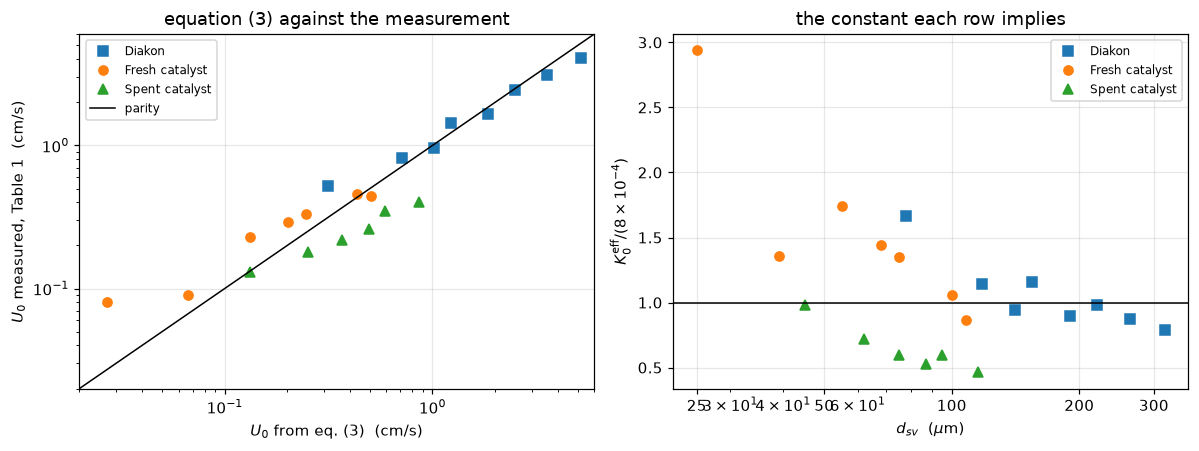

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
mk = {"Diakon": "s", "Fresh catalyst": "o", "Spent catalyst": "^"}
for name, grp in t1.loc[has_U0].groupby("powder"):
    ax[0].loglog(grp.U0_eq3, grp.U_0, mk[name], ms=6, label=name)
    ax[1].semilogx(grp.d_sv_um, grp.K0_ratio, mk[name], ms=6, label=name)
lim = [0.02, 6]
ax[0].plot(lim, lim, "k-", lw=1, label="parity")
ax[0].set(xlim=lim, ylim=lim, xlabel=r"$U_0$ from eq. (3)  (cm/s)",
          ylabel=r"$U_0$ measured, Table 1  (cm/s)",
          title="equation (3) against the measurement")
ax[1].axhline(1.0, color="k", lw=1)
ax[1].set(xlabel=r"$d_{sv}$  ($\mu$m)",
          ylabel=r"$K_0^{\rm eff} / (8\times10^{-4})$",
          title="the constant each row implies")
ax[1].set_xticks([25, 50, 100, 200, 300])
ax[1].set_xticklabels(["25", "50", "100", "200", "300"])
for a in ax:
    a.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 4. The bed-expansion columns, and the voidage Geldart does not print

Table 1 carries two more columns, $\varepsilon_{MB}$ and $H_{MB}/H_0$. **The
paper does not say how either was obtained** (section 4.2 describes the
measurement of $U_0$ and $U_{MB}$ and stops there) so they are treated here as
*reported*, and what follows is a transcription check on them and nothing more.
They are not independent of each other. The solids in the bed
are conserved between the settled state and the minimum bubbling state, so

$$H_0\,(1-\varepsilon_0) = H_{MB}\,(1-\varepsilon_{MB})
\qquad\Longrightarrow\qquad
\varepsilon_0 = 1 - (1-\varepsilon_{MB})\,\frac{H_{MB}}{H_0}.$$

Geldart prints neither $\varepsilon_0$ nor $H_0$, so this recovers a number the
paper does not state, and it is simultaneously a check on the two columns,
because an $\varepsilon_0$ outside about 0.35–0.65 would mean one of them is
mis-transcribed. Rows that print $H_{MB}/H_0 = 1.000$ make it sharper still:
they force $\varepsilon_0 = \varepsilon_{MB}$ exactly.

In [13]:
NOEXP = t1.index[t1.H_MB_over_H_0 == 1.000]      # fixed from the PRINTED table
EPS, e0 = eps_claims(t1, NOEXP)
t1["eps_0_inferred"] = e0
claims.value("eps0_inferred_min", EPS["eps0_inferred_min"], rtol=1e-6)
claims.value("eps0_inferred_max", EPS["eps0_inferred_max"], rtol=1e-6)
claims.bound("eps0_identity_residual", EPS["eps0_identity_residual"], max=1e-12, basis="identity",
             note="eps_0 = eps_MB algebraically where H_MB/H_0 = 1.000: a transcription check only")
EPS_MARGIN = float(min((e0 - EPS_RANGE[0]).min() / EPS_RANGE[0], (EPS_RANGE[1] - e0).min() / EPS_RANGE[1]))
claims.exact("eps0_rows_outside_range", EPS["eps0_rows_outside_range"], margin=EPS_MARGIN,
             min_margin=0.05, note=f"rows with eps_0 outside {EPS_RANGE[0]} to {EPS_RANGE[1]}")
dia = t1.loc[t1.rho_s_exact]
cat = t1.loc[~t1.rho_s_exact]
flat = dia.loc[NOEXP]                    # the coarsest Diakon fractions, H_MB/H_0 printed as 1.000
fall = dia.loc[dia.index < flat.index[0]]   # the finer ones
last_fall = dia.loc[flat.index[0] - 1]     # the coarsest of them, named by its label

display(t1[["powder", "d_sv_um", "eps_MB", "H_MB_over_H_0", "eps_0_inferred"]].round(4))
say(r"""All @@n_rows@@ rows give $\varepsilon_0$ between **@@lo@@** and **@@hi@@**,
@@n_out@@ of them outside 0.35–0.65, so every one is a physically admissible packed-bed
voidage. Diakon, the near-spherical powder, is tightest at **@@d_lo@@–@@d_hi@@**: it
falls @@mono@@ from @@f0@@ at @@s0@@ µm to @@f1@@ at @@s1@@ µm and is flat at
@@fl@@ for the @@n_flat@@ coarsest fractions, which is what a powder that packs
tighter as it coarsens should do. The two catalysts, irregular and porous, sit
higher at **@@c_lo@@–@@c_hi@@**. The @@n_flat@@ rows that print $H_{MB}/H_0 = 1.000$
return $\varepsilon_0 = \varepsilon_{MB}$ to **@@res@@**, but that one is
*structural*: with $H_{MB}/H_0$ exactly 1 the identity reduces to
$\varepsilon_0 = \varepsilon_{MB}$ algebraically, so it tests only that those cells
were transcribed as 1.000 and nothing else (it is a bound of 1e-12 here, and it
fails if either cell is mis-read, as break table 3 shows).

Note what this does **not** say. Geldart uses $\varepsilon_0 = 0.4$ in equation
(7); the powders in his own table sit at @@lo@@–@@hi@@, well above it. That is not a
contradiction (0.4 is stated for *large-particle* systems and Table 1 contains
none) but it does mean the table cannot check the $\varepsilon_0$ that
goes into the B/D boundary.

And note what it *rests* on. If $\varepsilon_{MB}$ was itself obtained from bed
height, the 200 g charge and $\rho_s$ (the natural route, though the paper does not
say) then for the @@n_cat@@ catalyst rows it inherits a $\rho_s$ printed as
approximate, and so does the $\varepsilon_0$ recovered from it. "Physically
admissible" above therefore means admissible given the printed numbers, not
verified.""",
    n_rows=N_ROWS, lo=f"{EPS['eps0_inferred_min']:.3f}", hi=f"{EPS['eps0_inferred_max']:.3f}",
    n_out=EPS["eps0_rows_outside_range"], d_lo=f"{dia.eps_0_inferred.min():.3f}",
    d_hi=f"{dia.eps_0_inferred.max():.3f}",
    mono="steadily" if bool((np.diff(fall.eps_0_inferred) < 0).all()) else "(not monotonically)",
    f0=f"{fall.eps_0_inferred.iloc[0]:.3f}", s0=f"{fall.d_sv_um.iloc[0]:.0f}",
    f1=f"{last_fall.eps_0_inferred:.3f}", s1=f"{last_fall.d_sv_um:.0f}",
    fl=f"{flat.eps_0_inferred.iloc[0]:.3f}", n_flat=len(flat),
    c_lo=f"{cat.eps_0_inferred.min():.3f}", c_hi=f"{cat.eps_0_inferred.max():.3f}",
    res=f"1e-12 at most (here {EPS['eps0_identity_residual']:.1e})", n_cat=len(cat))

,powder,d_sv_um,eps_MB,H_MB_over_H_0,eps_0_inferred
0,Diakon,78,0.542,1.095,0.4985
1,Diakon,118,0.496,1.065,0.4632
2,Diakon,141,0.481,1.040,0.4602
3,Diakon,155,0.465,1.012,0.4586
4,Diakon,190,0.452,1.003,0.4504
5,Diakon,220,0.442,1.001,0.4414
6,Diakon,263,0.444,1.000,0.4440
7,Diakon,318,0.444,1.000,0.4440
8,Fresh catalyst,25,0.645,1.430,0.4924
9,Fresh catalyst,39,0.629,1.370,0.4917


All 22 rows give $\varepsilon_0$ between **0.441** and **0.570**,
0 of them outside 0.35–0.65, so every one is a physically admissible packed-bed
voidage. Diakon, the near-spherical powder, is tightest at **0.441–0.498**: it
falls steadily from 0.498 at 78 µm to 0.441 at 220 µm and is flat at
0.444 for the 2 coarsest fractions, which is what a powder that packs
tighter as it coarsens should do. The two catalysts, irregular and porous, sit
higher at **0.492–0.570**. The 2 rows that print $H_{MB}/H_0 = 1.000$
return $\varepsilon_0 = \varepsilon_{MB}$ to **1e-12 at most (here 5.6e-17)**, but that one is
*structural*: with $H_{MB}/H_0$ exactly 1 the identity reduces to
$\varepsilon_0 = \varepsilon_{MB}$ algebraically, so it tests only that those cells
were transcribed as 1.000 and nothing else (it is a bound of 1e-12 here, and it
fails if either cell is mis-read, as break table 3 shows).

Note what this does **not** say. Geldart uses $\varepsilon_0 = 0.4$ in equation
(7); the powders in his own table sit at 0.441–0.570, well above it. That is not a
contradiction (0.4 is stated for *large-particle* systems and Table 1 contains
none) but it does mean the table cannot check the $\varepsilon_0$ that
goes into the B/D boundary.

And note what it *rests* on. If $\varepsilon_{MB}$ was itself obtained from bed
height, the 200 g charge and $\rho_s$ (the natural route, though the paper does not
say) then for the 14 catalyst rows it inherits a $\rho_s$ printed as
approximate, and so does the $\varepsilon_0$ recovered from it. "Physically
admissible" above therefore means admissible given the printed numbers, not
verified.

### 5. The B/D boundary is a cloud-existence condition

Read the two sides of equation (7) again:

$$\underbrace{\left(g\,\frac{d_B}{2}\right)^{1/2}}_{\text{bubble rise velocity}}
\;\le\;
\underbrace{\frac{8\times10^{-4}(\rho_s-\rho_f)\,g\,d_{sv}^2}{\mu\,\varepsilon_0}}_{
  \;=\;U_0/\varepsilon_0\;=\;\text{interstitial gas velocity}}$$

The right-hand side is equation (3) divided by $\varepsilon_0$, the interstitial
velocity, which E1.2 calls $u_f$. The left-hand side is $\tfrac{1}{\sqrt2}
\sqrt{g\,d_B} = 0.7071\sqrt{g\,d_B}$, and the Davies–Taylor rise velocity that
E1.2 uses is $u_{br} = 0.711\sqrt{g\,d_b}$. **They are the same formula to half a
percent.** Geldart's group D condition is therefore

$$u_{br} \le u_f \qquad\text{for } d_B = 25\ \text{cm},$$

which is precisely E1.2's no-cloud condition: the pole in
$(R_c/R)^3 = (u_{br}+2u_f)/(u_{br}-u_f)$.

**What is new here, and what is not.** That a bubble rising more slowly than the
interstitial gas carries no cloud is standard: E1.2 says it in those words, and
Geldart's section 3.4 and journal page 289 describe group D in exactly the same
physical terms, gas entering the base of the bubble and leaving the top. Geldart
never mentions Davidson, and E1.2's source (Kunii and Levenspiel 1968) predates
the classification, but the *equivalence in words* is in both places. What is
absent from both is the arithmetic: identifying equation (7)'s left-hand side
with the Davies–Taylor rise velocity and its right-hand side with $u_f$, and so
reading the printed group D line as E1.2's pole. Read that way, which is a
re-reading and not a new result, **the whole Geldart diagram is also a map of the
smallest bubble that can carry a cloud**,

$$d_b^{*} = \frac{1}{g}\left(\frac{u_f}{0.711}\right)^2
          = \frac{1}{g}\left(\frac{U_0}{0.711\,\varepsilon_0}\right)^2,$$

whose 25 cm contour is Geldart's line for group D. Below is that identity
checked three ways: the two rise-velocity coefficients compared, the contour
compared with equation (8), and a bubble actually solved on each side of the
line.

In [14]:
# (a) the two coefficients, and what the difference does to the boundary
c_geldart = u_br_geldart(P["d_B"]) / np.sqrt(P["g"] * P["d_B"])   # = 1/sqrt(2)
dt_pct = CONST["eq8_davies_taylor_vs_geldart_pct"]
C8_dt = C8 * (1 + dt_pct / 100)

say(r"""Geldart's coefficient is $1/\sqrt2 = @@cg@@$; Davies–Taylor is @@cd@@, a
difference of **@@dv@@ %** in velocity. Carried through equation (7) that moves
the boundary constant from **@@C8@@** to **@@C8dt@@**, **@@dt@@ %**, against the
**@@d8@@ %** by which Geldart rounded his own @@C8@@ to $10^6$. *The difference
between the two theories is smaller than the difference between Geldart's
arithmetic and Geldart's printed answer.*""",
    cg=f"{c_geldart:.4f}", cd=f"{P['c_ubr']:.4f}", dv=f"{dev_pct(P['c_ubr'], c_geldart):.2f}",
    C8=f"{C8:.4g}", C8dt=f"{C8_dt:.4g}", dt=f"{dt_pct:.2f}", d8=f"{d8:.2f}")

Geldart's coefficient is $1/\sqrt2 = 0.7071$; Davies–Taylor is 0.7110, a
difference of **0.55 %** in velocity. Carried through equation (7) that moves
the boundary constant from **1.016e+06** to **1.022e+06**, **0.55 %**, against the
**1.59 %** by which Geldart rounded his own 1.016e+06 to $10^6$. *The difference
between the two theories is smaller than the difference between Geldart's
arithmetic and Geldart's printed answer.*

In [15]:
# (b) three sands, one 25 cm bubble, on each side of the B/D line (E1.2's solve).
BED = {key: cloud_case(d_um, rho_s) for key, (d_um, rho_s) in BEDS.items()}
CLOUD = cloud_claims()
for name in ("cloud_RcR_sand_100um", "cloud_RcR_sand_600um"):
    claims.value(name, CLOUD[name], rtol=1e-6, note="E1.2's model, n = 1600, r_out = 20 R")
margin_700 = 1.0 - BED["sand_700um"]["ratio"]           # u_br/u_f below 1 by this much
claims.exact("cloud_absent_sand_700um", CLOUD["cloud_absent_sand_700um"], margin=margin_700,
             min_margin=0.05, note="no zero of W and u_br/u_f below 1")
claims.value("cloud_pymrm_vs_closed_form", CLOUD["cloud_pymrm_vs_closed_form"], rtol=0.05,
             note="discretisation error against E1.2's closed form, n = 1600")
grp_prod8 = [(r - P["rho_f"]) * d ** 2 for d, r in BEDS.values()]
claims.exact("cloud_beds_groups", CLOUD["cloud_beds_groups"],
             margin=min(abs(x / PRINTED["eq8"] - 1) for x in grp_prod8), min_margin=0.02,
             note="groups of the three sands from eqs. (6) and (8) as printed")
bd = pd.DataFrame([dict(bed=k, prod_eq6=(r - P["rho_f"]) * d, prod_eq8=(r - P["rho_f"]) * d ** 2,
                        group=group_of(d, r), U0=BED[k]["U0"], u_f=BED[k]["u_f"], u_br=BED[k]["u_br"],
                        ratio=BED[k]["ratio"], RcR_pymrm=BED[k]["RcR"], RcR_closed=BED[k]["closed"])
                   for k, (d, r) in BEDS.items()]).set_index("bed")
display(bd.round(4))
say(r"""Both group B powders get a cloud and the group D powder does not, and the
pymrm solve reports the absence as a **missing dividing streamline**, not as a
negative number. The cloud is a thin shell far inside group B ($R_c/R = @@r1@@$ at
100 µm) and swells as the powder approaches the line ($R_c/R = @@r2@@$ at 600 µm,
where $u_{br}/u_f$ is only @@q2@@), the pole seen from the inside. Where a cloud
exists the computed $R_c/R$ matches E1.2's closed form to **@@dev@@**; that is
discretisation error against a formula E1.2 already validated, not new evidence,
and it is reported only to show the port is faithful.""",
    r1=f"{CLOUD['cloud_RcR_sand_100um']:.3f}", r2=f"{CLOUD['cloud_RcR_sand_600um']:.2f}",
    q2=f"{BED['sand_600um']['ratio']:.2f}", dev=f"{CLOUD['cloud_pymrm_vs_closed_form']:.1e}")

,prod_eq6,prod_eq8,group,U0,u_f,u_br,ratio,RcR_pymrm,RcR_closed
bed,,,,,,,,,
sand_100um,259.88,25988.0,B,1.1331,2.8327,111.3459,39.3074,1.0255,1.0255
sand_600um,1559.28,935568.0,B,40.7908,101.9769,111.3459,1.0919,3.2286,3.2286
sand_700um,1819.16,1273412.0,D,55.5208,138.8019,111.3459,0.8022,NaN,NaN


Both group B powders get a cloud and the group D powder does not, and the
pymrm solve reports the absence as a **missing dividing streamline**, not as a
negative number. The cloud is a thin shell far inside group B ($R_c/R = 1.025$ at
100 µm) and swells as the powder approaches the line ($R_c/R = 3.23$ at 600 µm,
where $u_{br}/u_f$ is only 1.09), the pole seen from the inside. Where a cloud
exists the computed $R_c/R$ matches E1.2's closed form to **3.6e-07**; that is
discretisation error against a formula E1.2 already validated, not new evidence,
and it is reported only to show the port is faithful.

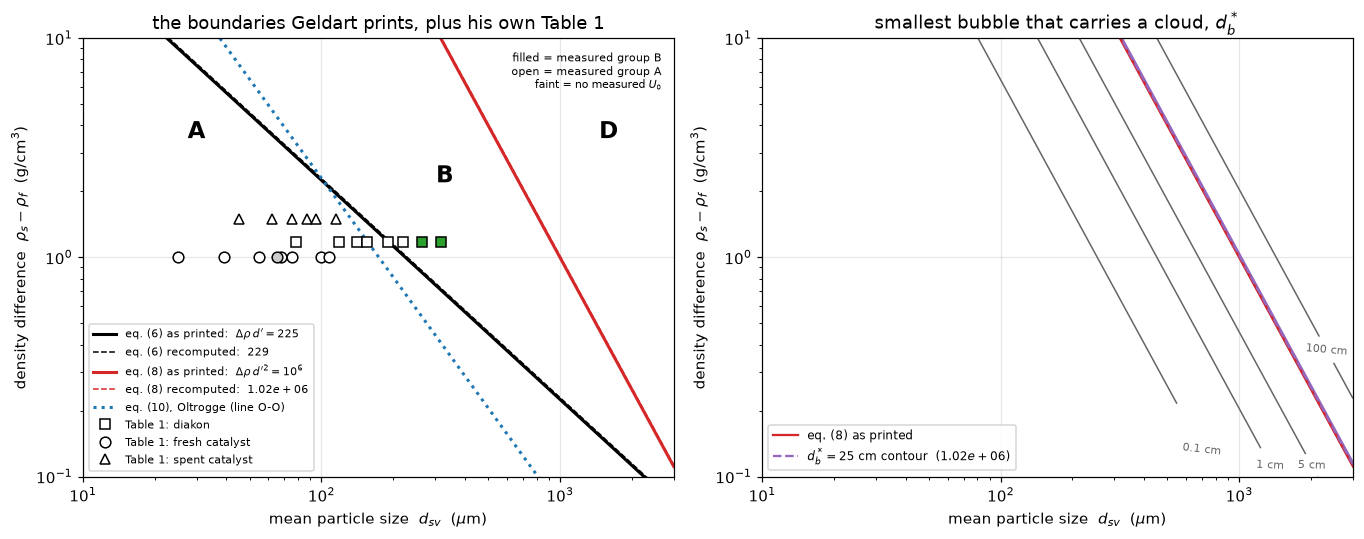

eq. (10) in (drho, d') form:  drho * d'^1.5 = 2299


In [16]:
# (c) the classification map, drawn ONLY from the printed equations.
d_grid = np.logspace(np.log10(10), np.log10(3000), 400)      # um
drho_grid = np.logspace(np.log10(0.1), np.log10(10), 400)    # g/cm3
DD, RR = np.meshgrid(d_grid, drho_grid)
db_star = (U_0_eq3(DD, RR) / (P["c_ubr"] * P["eps_0"])) ** 2 / P["g"]   # cm

fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.0))

# --- left: the diagram itself
a = ax[0]
a.loglog(d_grid, PRINTED["eq6"] / d_grid, "k-", lw=2,
         label=r"eq. (6) as printed:  $\Delta\rho\,d' = 225$")
a.loglog(d_grid, C6 / d_grid, "k--", lw=1,
         label=rf"eq. (6) recomputed:  ${C6:.0f}$")
a.loglog(d_grid, PRINTED["eq8"] / d_grid ** 2, "-", color="tab:red", lw=2,
         label=r"eq. (8) as printed:  $\Delta\rho\,d'^2 = 10^6$")
a.loglog(d_grid, C8 / d_grid ** 2, "--", color="tab:red", lw=1,
         label=rf"eq. (8) recomputed:  ${C8:.3g}$")
C10 = const_9_10(PRINTED["eq10"])
a.loglog(d_grid, C10 / d_grid ** 1.5, ":", color="tab:blue", lw=2,
         label=r"eq. (10), Oltrogge (line O-O)")
for name, grp in t1.groupby("powder"):
    for gletter, style in (("A", dict(mfc="w")), ("B", dict(mfc="tab:green")),
                           ("-", dict(mfc="0.8"))):
        s = grp[grp.group_meas == gletter]
        if len(s):
            a.loglog(s.d_sv_um, s.drho, mk[name], ms=7, mec="k", lw=0, label=None, **style)
for name in mk:                                   # marker key only, no data
    a.loglog([], [], mk[name], ms=7, mec="k", mfc="w", lw=0, label=f"Table 1: {name.lower()}")
a.set(xlim=(10, 3000), ylim=(0.1, 10),
      xlabel=r"mean particle size  $d_{sv}$  ($\mu$m)",
      ylabel=r"density difference  $\rho_s-\rho_f$  (g/cm$^3$)",
      title="the boundaries Geldart prints, plus his own Table 1")
for lbl, xy in [("A", (30, 3.5)), ("B", (330, 2.2)), ("D", (1600, 3.5))]:
    a.text(*xy, lbl, fontsize=15, weight="bold", ha="center")
a.legend(fontsize=7.5, loc="lower left")
a.text(0.98, 0.97, "filled = measured group B\nopen = measured group A\n"
       "faint = no measured $U_0$", transform=a.transAxes, fontsize=7, va="top", ha="right")

# --- right: the same plane as a cloud map
a = ax[1]
lv = [0.1, 1.0, 5.0, 100.0]
cs = a.contour(DD, RR, db_star, levels=lv, colors="0.4", linewidths=1)
a.clabel(cs, fmt=lambda v: f"{v:g} cm", fontsize=7)
a.contour(DD, RR, db_star, levels=[P["d_B"]], colors="tab:purple", linewidths=2.5)
a.loglog(d_grid, PRINTED["eq8"] / d_grid ** 2, "-", color="tab:red", lw=1.5, label=r"eq. (8) as printed")
a.loglog(d_grid, C8_dt / d_grid ** 2, "--", color="tab:purple", lw=1.5,
         label=rf"$d_b^*={P['d_B']:.0f}$ cm contour  (${C8_dt:.3g}$)")
a.set(xscale="log", yscale="log", xlim=(10, 3000), ylim=(0.1, 10),
      xlabel=r"mean particle size  $d_{sv}$  ($\mu$m)",
      ylabel=r"density difference  $\rho_s-\rho_f$  (g/cm$^3$)",
      title=r"smallest bubble that carries a cloud, $d_b^*$")
a.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()
print(f"eq. (10) in (drho, d') form:  drho * d'^1.5 = {C10:.0f}")

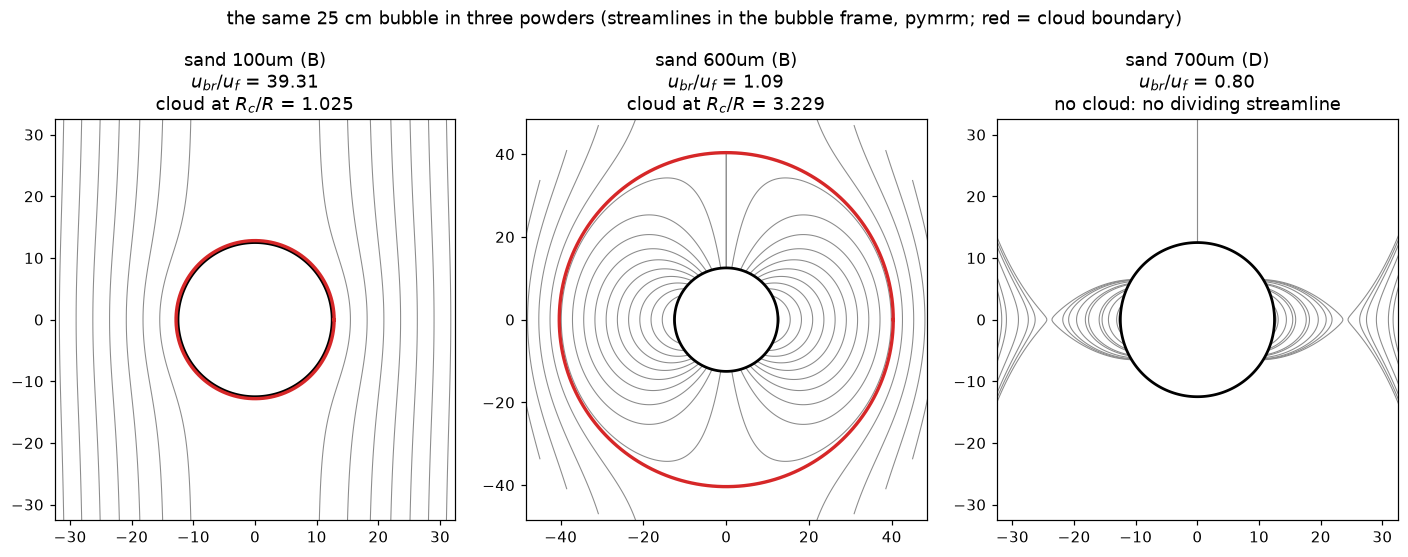

In [17]:
# (d) the cloud around the same 25 cm bubble in each powder, from the field.
fig, ax = plt.subplots(1, 3, figsize=(13, 4.6))
th = np.linspace(0, 2 * np.pi, 400)
for a, (key, b) in zip(ax, BED.items()):
    sol = b["sol"]; R = sol.R
    rmax = 4.5 * R
    rr = np.linspace(R, rmax, 400)
    Wi = sol.W_at(rr)                    # exact between faces: linear in r^-3
    TH, RG = np.meshgrid(np.linspace(0, np.pi, 300), rr)
    psi = 0.5 * RG ** 2 * Wi[:, None] * np.sin(TH) ** 2
    # levels chosen from the equatorial value of psi, so the streamlines are spread
    # evenly around the bubble instead of bunching in the far field
    r_seed = np.linspace(1.02 * R, 0.95 * rmax, 16)
    lv = np.unique(np.sort(0.5 * r_seed ** 2 * sol.W_at(r_seed)))
    lv = np.unique(np.concatenate([lv, [0.0]]))
    for sgn in (1, -1):
        a.contour(sgn * RG * np.sin(TH), RG * np.cos(TH), psi,
                  levels=lv, colors="0.55", linewidths=0.7, linestyles="solid")
    a.fill(R * np.cos(th), R * np.sin(th), color="w", ec="k", lw=1.8, zorder=3)
    if np.isfinite(b["RcR"]):
        Rc = b["RcR"] * R
        a.plot(Rc * np.cos(th), Rc * np.sin(th), "-", color="tab:red", lw=2.2, zorder=4)
        sub = f"cloud at $R_c/R$ = {b['RcR']:.3f}"
    else:
        sub = "no cloud: no dividing streamline"
    lim = 2.6 * R if not np.isfinite(b["RcR"]) else max(2.6 * R, 1.2 * b["RcR"] * R)
    a.set(aspect="equal", xlim=(-lim, lim), ylim=(-lim, lim),
          title=f"{key.replace('_', ' ')} ({group_of(*BEDS[key])})\n$u_{{br}}/u_f$ = {b['ratio']:.2f}\n{sub}")
    a.grid(False)
fig.suptitle(f"the same {P['d_B']:.0f} cm bubble in three powders "
             "(streamlines in the bubble frame, pymrm; red = cloud boundary)", y=1.04)
fig.tight_layout()
plt.show()

## Validation

Ranked as the gallery's brief ranks them, highest available first.

**Route 3: stated numerical results in the text.** Geldart works one example on
journal page 289 with printed intermediates, and states a size at which a
1 g cm$^{-3}$ powder turns from A to B. Both are reproduced below.

**Route 3: against measurement.** The A/B criterion against the measured
fractions of Table 1, and equation (3) against the measured $U_0$ column. These
are the only comparisons on the page that involve a measurement.

**Route 2: internal identities.** The two boundary constants recomputed from
the expressions they are derived from; the solids balance linking
$\varepsilon_{MB}$ and $H_{MB}/H_0$; the placement of equations (9) and (10)
relative to (6), against Geldart's prose about where they lie; the copy of
E1.2's model reproducing E1.2's stored cloud claims.

**Route 4: digitised figures.** Not used. Nothing on this page is digitised.

In [18]:
# --- V1: the worked example, journal page 289 -------------------------------
WK = worked()
for name, v in WK.items():
    claims.value(name, v, rtol=1e-6, note="closed-form arithmetic on the printed inputs")
U0_ex, UMB_ex = U_0_eq3(100.0, 1.0), U_MB_eq2(100.0)
U0_sand = U_0_eq3(100.0, 2.7 - P["rho_f"])
V1 = pd.DataFrame([
    ("U_0 at d'=100 um, drho=1 g/cm3 (eq. 3)", U0_ex, 0.43,
     "read off Fig. 2 by Geldart, so printed to 2 s.f."),
    ("U_MB at d'=100 um (eq. 2)", UMB_ex, 1.0, "exact by construction"),
    ("U_MB/U_0 at that point", UMB_ex / U0_ex, 2.33, "Geldart's 2.33 = 1/0.43, i.e. his graph-read U_0"),
    ("U_0 for 100 um sand, rho_s=2.7 (eq. 3)", U0_sand, 1.2, "printed to 2 s.f."),
    ("d' at which drho=1 turns A -> B", C6 / 1.0, 250.0, 'Geldart writes "about 250 um"'),
], columns=["quantity", "recomputed", "printed", "note"])
V1["dev_%"] = dev_pct(V1.recomputed, V1.printed)
display(V1[["quantity", "recomputed", "printed", "dev_%", "note"]].round(4))
four = V1["dev_%"].iloc[:4].abs()
say(r"""Four of the five land within **@@worst@@ %** of the printed value, which is all
two significant figures can resolve: the worst of the four is *@@which@@* at
@@w_dev@@ %. The ratio 2.33 is Geldart dividing by a number he read off a log-log
graph: $1/0.43 = @@inv@@$ against $1/@@u0@@ = @@ratio@@$. The fifth is different in
kind. His "about 250 µm" is @@x_dev@@ % from the @@x@@ µm his own equation (6)
gives, and $250 \times 1 = 250$ is on the group B side of both 225 and @@C6@@. It
is a loose sentence, not a slip in an equation: nothing downstream uses it.""",
    worst=f"{four.max():.1f}", which=V1.quantity[four.idxmax()],
    w_dev=f"{V1['dev_%'].iloc[:4][four.idxmax()]:+.2f}", inv=f"{1 / 0.43:.3f}",
    u0=f"{U0_ex:.4f}", ratio=f"{UMB_ex / U0_ex:.3f}", x_dev=f"{WK['worked_crossover_dev_pct']:+.1f}",
    x=f"{C6:.0f}", C6=f"{C6:.0f}")

,quantity,recomputed,printed,dev_%,note
0,"U_0 at d'=100 um, drho=1 g/cm3 (eq. 3)",0.4360,0.43,1.3953,"read off Fig. 2 by Geldart, so printed to 2 s.f."
1,U_MB at d'=100 um (eq. 2),1.0000,1.00,0.0000,exact by construction
2,U_MB/U_0 at that point,2.2936,2.33,-1.5632,"Geldart's 2.33 = 1/0.43, i.e. his graph-read U_0"
3,"U_0 for 100 um sand, rho_s=2.7 (eq. 3)",1.1767,1.20,-1.9436,printed to 2 s.f.
4,d' at which drho=1 turns A -> B,229.3578,250.00,-8.2569,"Geldart writes ""about 250 um"""


Four of the five land within **1.9 %** of the printed value, which is all
two significant figures can resolve: the worst of the four is *U_0 for 100 um sand, rho_s=2.7 (eq. 3)* at
-1.94 %. The ratio 2.33 is Geldart dividing by a number he read off a log-log
graph: $1/0.43 = 2.326$ against $1/0.4360 = 2.294$. The fifth is different in
kind. His "about 250 µm" is -8.3 % from the 229 µm his own equation (6)
gives, and $250 \times 1 = 250$ is on the group B side of both 225 and 229. It
is a loose sentence, not a slip in an equation: nothing downstream uses it.

In [19]:
# --- V2: where equations (9) and (10) sit, against Geldart's prose ----------
PL = placement()
C9, C10 = const_9_10(PRINTED["eq9"]), const_9_10(PRINTED["eq10"])
for name, v in PL.items():
    if name == "eq10_cross_inside_fig3_axes":
        continue
    claims.value(name, v, rtol=1e-6, note="closed-form arithmetic on the printed inputs")
x10, y10 = PL["eq10_crosses_XY_um"], PL["eq10_crosses_XY_drho"]
claims.exact("eq10_cross_inside_fig3_axes", PL["eq10_cross_inside_fig3_axes"],
             margin=min(np.log(x10 / FIG3_D[0]), np.log(FIG3_D[1] / x10),
                        np.log(y10 / FIG3_RHO[0]), np.log(FIG3_RHO[1] / y10)),
             min_margin=0.1, note="smallest log distance of the crossing to a labelled axis end")
place = pd.DataFrame(
    [(r, (C9 / r) ** (2 / 3), (C10 / r) ** (2 / 3), PRINTED["eq6"] / r,
      ((C9 / r) ** (2 / 3)) / (PRINTED["eq6"] / r))
     for r in (FIG3_RHO[1], 1.0, FIG3_RHO[0])],
    columns=["drho (g/cm3)", "eq. (9)  d' (um)", "eq. (10)  d' (um)",
             "line XY  d' (um)", "eq.(9) / XY, in size"])
display(place.round(2))
d9_if_500 = placement(K9=500.0)["eq9_size_at_drho1_um"]      # eq. (9) with 5000 mis-read
say(r"""In $(\Delta\rho, d')$ coordinates the two competing criteria are
$\Delta\rho\,d'^{1.5} = @@C9@@$ (Verloop and Heertjes, eq. 9) and
$\Delta\rho\,d'^{1.5} = @@C10@@$ (Oltrogge, eq. 10). Both are steeper in $d'$ than
Geldart's line XY, so each meets XY exactly once:

* **eq. (10) crosses XY at $d' = @@x10@@$ µm, $\Delta\rho = @@y10@@$ g/cm³**, inside
  both of Figure 3's labelled axis ranges (@@d0@@–@@d1@@ µm, @@r0@@–@@r1@@ g/cm³),
  consistent with Geldart drawing it there as line O–O and calling it as good as
  eqn. (5);
* **eq. (9) crosses XY at $d' = @@x9@@$ µm, $\Delta\rho = @@y9@@$ g/cm³**, which is
  off the labelled diagram in both coordinates: @@over@@ times beyond the right end
  of the labelled abscissa and @@under@@ times below the lower end of the labelled
  ordinate. **That crossing point is therefore not evidence about what is on the
  page.**

What the crossing does establish is that the two lines never meet inside the
diagram, so eq. (9) lies to the right of XY throughout it (the ratio of their sizes
is monotone in $\Delta\rho$, so the two ends of the labelled ordinate bound it): by
a factor @@top@@ in size at the top of the labelled ordinate and @@bottom@@ at the
bottom. The line itself is **not off-scale**: at $\Delta\rho = 1$ g/cm³ it sits at
@@d9@@ µm against XY's @@xy@@ µm, both inside the labelled abscissa. So Geldart's
"lies much too far to the right" is a statement about its distance from XY and
from his data points, not about it running off the axis; that it "is not shown on
Fig. 3" is his statement about his own drawing, and nothing here checks it.

The placement has teeth: read the 5000 of eq. (9) as 500 and it lands at @@d9b@@ µm
at $\Delta\rho = 1$, i.e. to the *left* of XY, inverting the conclusion entirely.""",
    C9=f"{C9:.0f}", C10=f"{C10:.0f}", x10=f"{x10:.0f}", y10=f"{y10:.2f}", d0=f"{FIG3_D[0]:.0f}",
    d1=f"{FIG3_D[1]:.0f}", r0=FIG3_RHO[0], r1=f"{FIG3_RHO[1]:.0f}", x9=f"{PL['eq9_crosses_XY_um']:.0f}",
    y9=f"{PL['eq9_crosses_XY_drho']:.4f}", over=f"{PL['eq9_cross_size_over_axis_max']:.1f}",
    under=f"{PL['eq9_cross_axis_min_over_drho']:.1f}", top=f"{PL['eq9_over_XY_size_ratio_top']:.1f}",
    bottom=f"{PL['eq9_over_XY_size_ratio_bottom']:.1f}", d9=f"{PL['eq9_size_at_drho1_um']:.0f}",
    xy=f"{PRINTED['eq6']:.0f}", d9b=f"{d9_if_500:.0f}")

,drho (g/cm3),eq. (9) d' (um),eq. (10) d' (um),line XY d' (um),"eq.(9) / XY, in size"
0,7.0,256.37,47.60,32.14,7.98
1,1.0,938.15,174.18,225.00,4.17
2,0.2,2743.17,509.31,1125.00,2.44


In $(\Delta\rho, d')$ coordinates the two competing criteria are
$\Delta\rho\,d'^{1.5} = 28735$ (Verloop and Heertjes, eq. 9) and
$\Delta\rho\,d'^{1.5} = 2299$ (Oltrogge, eq. 10). Both are steeper in $d'$ than
Geldart's line XY, so each meets XY exactly once:

* **eq. (10) crosses XY at $d' = 104$ µm, $\Delta\rho = 2.16$ g/cm³**, inside
  both of Figure 3's labelled axis ranges (20–1000 µm, 0.2–7 g/cm³),
  consistent with Geldart drawing it there as line O–O and calling it as good as
  eqn. (5);
* **eq. (9) crosses XY at $d' = 16310$ µm, $\Delta\rho = 0.0138$ g/cm³**, which is
  off the labelled diagram in both coordinates: 16.3 times beyond the right end
  of the labelled abscissa and 14.5 times below the lower end of the labelled
  ordinate. **That crossing point is therefore not evidence about what is on the
  page.**

What the crossing does establish is that the two lines never meet inside the
diagram, so eq. (9) lies to the right of XY throughout it (the ratio of their sizes
is monotone in $\Delta\rho$, so the two ends of the labelled ordinate bound it): by
a factor 8.0 in size at the top of the labelled ordinate and 2.4 at the
bottom. The line itself is **not off-scale**: at $\Delta\rho = 1$ g/cm³ it sits at
938 µm against XY's 225 µm, both inside the labelled abscissa. So Geldart's
"lies much too far to the right" is a statement about its distance from XY and
from his data points, not about it running off the axis; that it "is not shown on
Fig. 3" is his statement about his own drawing, and nothing here checks it.

The placement has teeth: read the 5000 of eq. (9) as 500 and it lands at 202 µm
at $\Delta\rho = 1$, i.e. to the *left* of XY, inverting the conclusion entirely.

In [20]:
# --- V3: the copy of E1.2's model reproduces E1.2's own stored cloud claims -
E12 = load_claims(PAGE_E12)
D_C, U_MF_C, EPS_C = 3.7, 2.1, 0.50       # appendix C of Kunii and Levenspiel, as E1.2 sets it up
E12_RTOL = dict(Rc_over_R_C=1e-6, Rc_rel_error_n1600=0.05)   # the rtol E1.2 gives those two claims


def e12_reproduction(n=1600, c_ubr=0.711, **model_kw):
    """The same cloud, with E1.2's inputs and grid; the relative gap to E1.2's stored claims."""
    u_br = rise_velocity(D_C, c_ubr=c_ubr)                    # E1.2's own default g
    sol = DavidsonBubble(D_C / 2, U_MF_C / EPS_C, u_br, n=n, r_out_mult=20.0, **model_kw).solve()
    rc = sol.cloud_radius()
    err = abs(rc - sol.R * cloud_radius_exact(sol.u_f, sol.u_br)) / sol.R
    return {"cloud_copy_vs_E12_Rc_over_R": abs(rc / sol.R / E12["Rc_over_R_C"] - 1),
            "cloud_copy_vs_E12_Rc_error": abs(err / E12["Rc_rel_error_n1600"] - 1)}


COPY = e12_reproduction()
claims.bound("cloud_copy_vs_E12_Rc_over_R", COPY["cloud_copy_vs_E12_Rc_over_R"],
             max=E12_RTOL["Rc_over_R_C"], basis="chosen",
             note="E1.2's claim Rc_over_R_C, relative gap, held to that claim's own rtol")
claims.bound("cloud_copy_vs_E12_Rc_error", COPY["cloud_copy_vs_E12_Rc_error"],
             max=E12_RTOL["Rc_rel_error_n1600"], basis="chosen",
             note="E1.2's claim Rc_rel_error_n1600, relative gap, held to that claim's own rtol")
say(r"""The copy of E1.2's `model.py` reproduces that page's stored cloud claims on
E1.2's own inputs (appendix C of Kunii and Levenspiel: $d_b = @@d@@$ cm, $u_{mf} =
@@u@@$ cm/s, $\varepsilon_{mf} = @@e@@$, @@n@@ cells, $r_{out} = 20R$): $R_c/R$ to a
relative gap below @@b1@@ (here @@g1@@) and the truncation error against the closed
form to a relative gap below @@b2@@ (here @@g2@@). Each bound is the `rtol` E1.2
gives that claim, not a result of this page; the gaps are round-off between two
runs of the same code.""",
    d=D_C, u=U_MF_C, e=EPS_C, n=1600, g1=f"{COPY['cloud_copy_vs_E12_Rc_over_R']:.1e}",
    g2=f"{COPY['cloud_copy_vs_E12_Rc_error']:.1e}", b1=f"{E12_RTOL['Rc_over_R_C']:g}",
    b2=f"{E12_RTOL['Rc_rel_error_n1600']:g}")

The copy of E1.2's `model.py` reproduces that page's stored cloud claims on
E1.2's own inputs (appendix C of Kunii and Levenspiel: $d_b = 3.7$ cm, $u_{mf} =
2.1$ cm/s, $\varepsilon_{mf} = 0.5$, 1600 cells, $r_{out} = 20R$): $R_c/R$ to a
relative gap below 1e-06 (here 0.0e+00) and the truncation error against the closed
form to a relative gap below 0.05 (here 0.0e+00). Each bound is the `rtol` E1.2
gives that claim, not a result of this page; the gaps are round-off between two
runs of the same code.

In [21]:
# --- V4: equation (2) against the U_MB column: a FIT RESIDUAL, reported as such.
GRP_A = (t1.group_meas == "A").to_numpy()
EQ2, res2 = eq2_claims(t1, GRP_A)
claims.value("eq2_fit_residual_mean_abs_pct", EQ2["eq2_fit_residual_mean_abs_pct"], rtol=1e-6)
worst2 = res2[GRP_A].abs().idxmax()                 # the row with the largest residual, by name
say(r"""Equation (2), $U_{MB} = 100\,d_{sv}$, against the $U_{MB}$ column it was drawn
through: mean absolute deviation **@@mean@@ %** over the @@n@@ rows measured group
A, worst **@@worst@@ %** (the @@d@@ µm @@powder@@ fraction). Over all @@n_rows@@ rows
it is @@mean_all@@ % mean, @@max_all@@ % worst. **This is the residual of a line to
the points it was fitted through.** It says the relation is simple and the scatter
is real; it is not evidence that equation (2) predicts anything, and it is not
counted anywhere on this page as agreement.""",
    mean=f"{EQ2['eq2_fit_residual_mean_abs_pct']:.1f}", n=int(GRP_A.sum()),
    worst=f"{res2[GRP_A].abs().max():.1f}", d=f"{t1.d_sv_um[worst2]:.0f}",
    powder=t1.powder[worst2].lower(), n_rows=N_ROWS, mean_all=f"{res2.abs().mean():.1f}",
    max_all=f"{res2.abs().max():.1f}")

Equation (2), $U_{MB} = 100\,d_{sv}$, against the $U_{MB}$ column it was drawn
through: mean absolute deviation **9.6 %** over the 19 rows measured group
A, worst **36.9 %** (the 115 µm spent catalyst fraction). Over all 22 rows
it is 10.1 % mean, 36.9 % worst. **This is the residual of a line to
the points it was fitted through.** It says the relation is simple and the scatter
is real; it is not evidence that equation (2) predicts anything, and it is not
counted anywhere on this page as agreement.

### Make sure the checks can fail

Every number registered above is attacked. Each row injects one defect through a
call argument or a physical parameter, everywhere the parameter enters, and
records which claims fail their own check; the row labels are built from the
call. A defect that leaves a claim unmoved is a blind spot and is named as one.

The tables cover, in order: the boundary constants, the worked example and the
placement of equations (9) and (10); the Table 1 classification; the two
column-based checks; and the cloud solve with its copy of E1.2.

In [22]:
# --- BREAK TABLE 1: constants, worked example, placement of eqs. (9) and (10) -
def p_label(**kw):
    """Row label built from the arguments: 'name: baseline -> injected'."""
    base = {**P, "d_ubr": P["d_B"]}
    return "; ".join(f"{k}: {base[k]:g} -> {v:g}" for k, v in kw.items())


def constants_row(**kw):
    p, d_ubr = dict(P), kw.pop("d_ubr", None)
    p.update(kw)
    return {**constants(p, d_ubr), **worked(p), **placement(p), **shift_effects(p)}


rows1 = [dict(mu=1.8e-3), dict(mu=1.8e-5), dict(K_MB=10.0), dict(C3=8.0e-3), dict(g=9.81),
         dict(eps_0=0.5), dict(d_B=50.0), dict(c_ubr=0.5), dict(rho_f=0.0),
         dict(d_ubr=0.5 * P["d_B"])]
out1 = []
for kw in rows1:
    got = constants_row(**dict(kw))
    caught = brk_all(p_label(**kw), got)
    out1.append((p_label(**kw), got["eq6_constant_recomputed"], got["eq6_constant_dev_pct"],
                 got["eq8_constant_recomputed"], got["eq8_constant_dev_pct"],
                 got["eq8_davies_taylor_vs_geldart_pct"], sum(caught.values()), len(caught)))
plc = [dict(K9=500.0), dict(K10=4000.0), dict(xy=22.5)]
for kw in plc:
    lab = "; ".join(f"{k}: {({'K9': PRINTED['eq9'], 'K10': PRINTED['eq10'], 'xy': PRINTED['eq6']})[k]:g} -> {v:g}"
                    for k, v in kw.items())
    got = placement(**kw)
    caught = brk_all(lab, got)
    out1.append((lab, np.nan, np.nan, np.nan, np.nan, np.nan, sum(caught.values()), len(caught)))
B1 = pd.DataFrame([("baseline", C6, d6, C8, d8, dt_pct, 0, 0)] + out1,
                  columns=["injected defect", "eq6 const", "dev_% vs 225", "eq8 const",
                           "dev_% vs 1e6", "DT shift %", "claims failing", "claims of the call"])
display(B1.round(2))
# the smallest effect any of the rows with a physical misreading has on a constant
SHIFT = {}
for kw in rows1:
    got = constants_row(**dict(kw))
    SHIFT[p_label(**kw)] = (dev_pct(got["eq6_constant_recomputed"], C6),
                            dev_pct(got["eq8_constant_recomputed"], C8))
SHIFT_ARR = np.array(list(SHIFT.values()))
RHOF_ROW = p_label(rho_f=0.0)
EPS_ROW, DB_ROW = p_label(eps_0=0.5), p_label(d_B=50.0)

,injected defect,eq6 const,dev_% vs 225,eq8 const,dev_% vs 1e6,DT shift %,claims failing,claims of the call
0,baseline,229.36,1.94,1015928.19,1.59,0.55,0,0
1,mu: 0.00018 -> 0.0018,2293.58,919.37,10159281.92,915.93,0.55,19,22
2,mu: 0.00018 -> 1.8e-05,22.94,-89.81,101592.82,-89.84,0.55,19,22
3,K_MB: 100 -> 10,22.94,-89.81,1015928.19,1.59,0.55,5,22
4,C3: 0.0008 -> 0.008,22.94,-89.81,101592.82,-89.84,0.55,9,22
5,g: 981 -> 9.81,22935.78,10093.68,10159281.92,915.93,0.55,19,22
6,eps_0: 0.4 -> 0.5,229.36,1.94,1269910.24,26.99,0.55,3,22
7,d_B: 25 -> 50,229.36,1.94,1436739.43,43.67,0.55,3,22
8,c_ubr: 0.711 -> 0.5,229.36,1.94,1015928.19,1.59,-29.29,1,22
9,rho_f: 0.0012 -> 0,229.36,1.94,1015928.19,1.59,0.55,1,22


In [23]:
# --- BREAK TABLE 2: the Table 1 A/B classification and the boundary gaps ----
def ab_all(df, p=P, thr6=PRINTED["eq6"], thr8=PRINTED["eq8"], **kw):
    """All claim values of section 2 under one defect."""
    got = ab_scores(df, p, thr=thr6, **kw)
    got.update(gap_counts(df, p, thr6=thr6, thr8=thr8, size=kw.get("size"))[0])
    got.update(boundary_rows(df, p, thr=thr6, **kw)[0])
    got.update(low_rows(df, p, size=kw.get("size"), dens=kw.get("dens"))[0])
    return got


def edit_cell(df, rowsel, col, f):
    """A copy of ``df`` with column ``col`` of the row ``rowsel`` replaced by ``f(old)``;
    returns it with a label naming the row and both values."""
    out, i = df.copy(), df.index[rowsel][0]
    old, new = out.loc[i, col], f(out.loc[i, col])
    out.loc[i, col] = new
    return out, f"{col} of the {out.loc[i, 'd_sv_um']:.0f} um {out.loc[i, 'powder'].lower()} row: {old:g} -> {new:g}"


no_dash = t1.assign(U_0=t1.U_0.fillna(0.0))
tie_df, tie_lab = edit_cell(t1, (t1.ratio_meas == 1.0).to_numpy() & (t1.d_sv_um == 263).to_numpy(),
                            "U_MB", lambda v: round(v - 0.01, 2))
dia78_df, dia78_lab = edit_cell(t1, (t1.d_sv_um == 78).to_numpy(), "U_0", lambda v: np.nan)
exact_df, exact_lab = edit_cell(t1, (t1.d_sv_um == 78).to_numpy(), "rho_s_exact", lambda v: not v)
rows2 = [("REFERENCE: the null model, group A for everything (thr6: 225 -> inf)", dict(thr6=np.inf)),
         (f"thr6: 225 -> {C6:.1f} (the recomputed constant)", dict(thr6=C6)),
         ("thr6: 225 -> 150", dict(thr6=150.0)),
         ("thr6: 225 -> 500", dict(thr6=500.0)),
         ("thr6: 225 -> 2250 (decimal slip)", dict(thr6=2250.0)),
         ("thr8: 1e6 -> 1e5", dict(thr8=1.0e5)),
         ("criterion inverted (A when the product exceeds 225)", dict(invert=True)),
         ("dens: rho_s - rho_f -> rho_s", dict(dens=t1.rho_s)),
         ("size: d' in um -> d' left in cm", dict(size=t1.d_sv_um * 1e-4)),
         ("U_0 and U_MB columns swapped", dict(swap=True)),
         ("U_0 of the em-dash row: missing -> 0", dict(df=no_dash)),
         (tie_lab, dict(df=tie_df)),
         (dia78_lab, dict(df=dia78_df)),
         (exact_lab, dict(df=exact_df)),
         ("Table 1 transcribed without its last row", dict(df=t1.iloc[:-1]))]
out2 = []
for lab, kw in rows2:
    kw = dict(kw)
    df = kw.pop("df", t1)
    got = ab_all(df, **kw)
    caught = brk_all(lab, got)
    out2.append((lab, f"{got['AB_rows_agreeing']}/{got['AB_rows_compared']}",
                 f"{got['AB_rows_agreeing_diakon']}/{got['AB_rows_compared_diakon']}",
                 f"{got['AB_discriminating_rows_agreeing']}/{got['AB_discriminating_rows']}",
                 sum(caught.values()), len(caught)))
BASE2 = ab_all(t1)
B2 = pd.DataFrame([("baseline: eq. (6) as printed, tie-break >",
                    f"{BASE2['AB_rows_agreeing']}/{BASE2['AB_rows_compared']}",
                    f"{BASE2['AB_rows_agreeing_diakon']}/{BASE2['AB_rows_compared_diakon']}",
                    f"{BASE2['AB_discriminating_rows_agreeing']}/{BASE2['AB_discriminating_rows']}", 0, 0),
                   ("TIE-BREAK: eq. (4) applied as displayed, >= not > (not a defect)",
                    f"{BASE2['AB_rows_agreeing_nonstrict']}/{BASE2['AB_rows_compared']}",
                    f"{BASE2['AB_rows_agreeing_diakon_nonstrict']}/{BASE2['AB_rows_compared_diakon']}",
                    f"{BASE2['AB_discriminating_rows_agreeing_nonstrict']}/{BASE2['AB_discriminating_rows']}", 0, 0)]
                  + out2,
                  columns=["injected defect", "all rows agreeing", "Diakon only",
                           "rows eq. (6) calls B", "claims failing", "claims of the call"])
display(B2)
N_BELOW, N_BELOW_CMP = LOWS["AB_rows_at_most_150"], LOWS["AB_rows_at_most_150_comparable"]
say(r"""Two rows here are not defects and are the most important in the table. The
TIE-BREAK row is the fork described in the results section: eq. (4) is
DISPLAYED as $U_{MB}/U_0 \ge 1$, and applying it that way costs the @@n_tie@@ rows
that print $U_{MB} = U_0$ exactly. Section 4.3 says those fractions are group B,
so the strict reading is the right one, but a reader who reimplements from the
displayed inequality will get this row's numbers, not the baseline's, and would
otherwise think the baseline invented. The REFERENCE row is a predictor that
ignores the data entirely. Every score in this table has to be read against it,
not against a notional perfect score, because the classes here are badly
unbalanced.

The Diakon column is the one with power. @@n_cmp_below@@ of the @@n_cmp@@ rows
with a measured $U_0$ (@@n_below@@ of the @@n_rows@@ rows) have a product of at
most @@low@@, the lowest boundary mis-read above, so no mis-reading of the
boundary at or above @@low@@ moves their verdict and the whole-table score changes
little; Diakon is the only series that CROSSES the line, which is why Geldart chose
it, section 5: "It is particularly desirable to choose series of size fractions
which cross over the line representing eqn. (6). This was achieved with Diakon."
""", n_tie=BASE2["AB_tie_rows"], n_cmp_below=N_BELOW_CMP, n_cmp=BASE2["AB_rows_compared"],
    n_below=N_BELOW, n_rows=N_ROWS, low=f"{LOW:.0f}")

,injected defect,all rows agreeing,Diakon only,rows eq. (6) calls B,claims failing,claims of the call
0,"baseline: eq. (6) as printed, tie-break >",20/21,7/8,2/3,0,0
1,"TIE-BREAK: eq. (4) applied as displayed, >= no...",18/21,5/8,0/3,0,0
2,"REFERENCE: the null model, group A for everyth...",19/21,6/8,0/0,12,27
3,thr6: 225 -> 229.4 (the recomputed constant),20/21,7/8,2/3,2,27
4,thr6: 225 -> 150,16/21,4/8,2/7,12,27
5,thr6: 225 -> 500,19/21,6/8,0/0,12,27
6,thr6: 225 -> 2250 (decimal slip),19/21,6/8,0/0,12,27
7,thr8: 1e6 -> 1e5,20/21,7/8,2/3,2,27
8,criterion inverted (A when the product exceeds...,1/21,1/8,0/18,9,27
9,dens: rho_s - rho_f -> rho_s,20/21,7/8,2/3,3,27


Two rows here are not defects and are the most important in the table. The
TIE-BREAK row is the fork described in the results section: eq. (4) is
DISPLAYED as $U_{MB}/U_0 \ge 1$, and applying it that way costs the 2 rows
that print $U_{MB} = U_0$ exactly. Section 4.3 says those fractions are group B,
so the strict reading is the right one, but a reader who reimplements from the
displayed inequality will get this row's numbers, not the baseline's, and would
otherwise think the baseline invented. The REFERENCE row is a predictor that
ignores the data entirely. Every score in this table has to be read against it,
not against a notional perfect score, because the classes here are badly
unbalanced.

The Diakon column is the one with power. 14 of the 21 rows
with a measured $U_0$ (15 of the 22 rows) have a product of at
most 150, the lowest boundary mis-read above, so no mis-reading of the
boundary at or above 150 moves their verdict and the whole-table score changes
little; Diakon is the only series that CROSSES the line, which is why Geldart chose
it, section 5: "It is particularly desirable to choose series of size fractions
which cross over the line representing eqn. (6). This was achieved with Diakon."


In [24]:
# --- BREAK TABLE 3a: what eq. (3) is worth, K0_eff / 8e-4 --------------------
rows3 = [dict(exponent=1.0), dict(exponent=3.0), dict(dens="rho_s"), dict(mu=1.8e-3), dict(C3=8.0e-3),
         dict(g=9.81), dict(U_0="U_MB"), dict(d_sv_um=1e-4)]
out3 = []
for kw in rows3:
    kw = dict(kw)
    p, df = dict(P), t1
    if "mu" in kw or "C3" in kw or "g" in kw:
        p.update({k: kw.pop(k) for k in ("mu", "C3", "g") if k in kw})
    if kw.pop("U_0", None) == "U_MB":
        df = t1.assign(U_0=t1.U_MB)
    if "d_sv_um" in kw:
        df = t1.assign(d_sv_um=t1.d_sv_um * kw.pop("d_sv_um"))
        shown_extra = "d_sv_um column: um -> cm"
    else:
        shown_extra = ""
    dens = df["rho_s"] if kw.pop("dens", None) == "rho_s" else None
    got, _ = k0_claims(df, p, dens=dens, **kw)
    got.update(eq3_exponent_effects(df, p, dens))
    base = {"exponent": 2.0, "mu": P["mu"], "C3": P["C3"], "g": P["g"]}
    lab = "; ".join(f"{k}: {base[k]:g} -> {v:g}" for k, v in {**{k: p[k] for k in ("mu", "C3", "g") if p[k] != P[k]},
                                                              **kw}.items())
    lab = lab or shown_extra or ("dens: rho_s - rho_f -> rho_s" if dens is not None else "U_0 column: measured -> the U_MB column")
    caught = brk_all(lab, got)
    out3.append((lab, got["eq3_K0eff_ratio_median"], got["eq3_K0eff_ratio_min"], got["eq3_K0eff_ratio_max"],
                 got["eq3_K0eff_spread_factor"], sum(caught.values()), len(caught)))
B3a = pd.DataFrame([("baseline", K0["eq3_K0eff_ratio_median"], K0["eq3_K0eff_ratio_min"],
                     K0["eq3_K0eff_ratio_max"], K0["eq3_K0eff_spread_factor"], 0, 0)] + out3,
                   columns=["injected defect", "median", "min", "max", "spread factor",
                            "claims failing", "claims of the call"])
display(B3a.round(3))

# --- BREAK TABLE 3b: the bed-expansion columns -------------------------------
def eps_row(df):
    got, _ = eps_claims(df, NOEXP)
    return got


diak190 = (t1.d_sv_um == 190).to_numpy()
fresh25 = ((t1.d_sv_um == 25) & (t1.powder == "Fresh catalyst")).to_numpy()
df_a, lab_a = edit_cell(t1, diak190, "eps_MB", lambda v: round(v + 0.10, 3))
df_b, lab_b = edit_cell(t1, diak190, "eps_MB", lambda v: round(v * 0.1, 4))
df_c, lab_c = edit_cell(t1, fresh25, "H_MB_over_H_0", lambda v: 3.0 * v)
fresh68 = ((t1.d_sv_um == 68) & (t1.powder == "Fresh catalyst")).to_numpy()
df_e, lab_e = edit_cell(t1, fresh68, "eps_MB", lambda v: round(v + 0.10, 3))
df_d = t1.copy()
df_d.loc[NOEXP, "H_MB_over_H_0"] = 1.05
lab_d = f"H_MB/H_0 of the {len(NOEXP)} rows printing 1.000: 1 -> 1.05"
out3b = []
for lab, df in [(lab_a, df_a), (lab_e, df_e), (lab_b, df_b), (lab_c, df_c), (lab_d, df_d)]:
    got = eps_row(df)
    caught = brk_all(lab, got)
    out3b.append((lab, got["eps0_inferred_min"], got["eps0_inferred_max"], got["eps0_rows_outside_range"],
                  got["eps0_identity_residual"], sum(caught.values()), len(caught)))
B3b = pd.DataFrame([("baseline", EPS["eps0_inferred_min"], EPS["eps0_inferred_max"], 0,
                     EPS["eps0_identity_residual"], 0, 0)] + out3b,
                   columns=["injected defect", "eps_0 min", "eps_0 max", "rows outside range",
                            "identity gap", "claims failing", "claims of the call"])
display(B3b.round(4))

# --- BREAK TABLE 3c: eq. (2) residual -----------------------------------------
out3c = []
for kw in (dict(K_MB=10.0), dict(K_MB=1000.0)):
    got, _ = eq2_claims(t1, GRP_A, dict(P, **kw))
    lab = "; ".join(f"{k}: {P[k]:g} -> {v:g}" for k, v in kw.items())
    caught = brk_all(lab, got)
    out3c.append((lab, got["eq2_fit_residual_mean_abs_pct"], sum(caught.values())))
display(pd.DataFrame([("baseline", EQ2["eq2_fit_residual_mean_abs_pct"], 0)] + out3c,
                     columns=["injected defect", "mean |residual| %", "claims failing"]).round(2))

,injected defect,median,min,max,spread factor,claims failing,claims of the call
0,baseline,9.810000e-01,4.630000e-01,2.939000e+00,6.351,0,0
1,exponent: 2 -> 1,1.000000e-02,4.000000e-03,2.500000e-02,5.688,12,17
2,exponent: 2 -> 3,8.020800e+01,2.486800e+01,1.175723e+03,47.279,12,17
3,dens: rho_s - rho_f -> rho_s,9.800000e-01,4.620000e-01,2.936000e+00,6.348,15,17
4,mu: 0.00018 -> 0.0018,9.809000e+00,4.628000e+00,2.939300e+01,6.351,10,17
5,C3: 0.0008 -> 0.008,9.800000e-02,4.600000e-02,2.940000e-01,6.351,10,17
6,g: 981 -> 9.81,9.808800e+01,4.628400e+01,2.939310e+02,6.351,10,17
7,U_0 column: measured -> the U_MB column,1.840000e+00,7.910000e-01,9.185000e+00,11.615,14,17
8,d_sv_um column: um -> cm,9.808844e+07,4.628435e+07,2.939307e+08,6.351,13,17


,injected defect,eps_0 min,eps_0 max,rows outside range,identity gap,claims failing,claims of the call
0,baseline,0.4414,0.5704,0,0.0000,0,0
1,eps_MB of the 190 um diakon row: 0.452 -> 0.552,0.4414,0.5704,0,0.0000,0,4
2,eps_MB of the 68 um fresh catalyst row: 0.645 ...,0.4414,0.6914,1,0.0000,2,4
3,eps_MB of the 190 um diakon row: 0.452 -> 0.0452,0.0423,0.5704,1,0.0000,2,4
4,H_MB_over_H_0 of the 25 um fresh catalyst row:...,-0.5230,0.5704,1,0.0000,2,4
5,H_MB/H_0 of the 2 rows printing 1.000: 1 -> 1.05,0.4162,0.5704,0,0.0278,2,4


,injected defect,mean |residual| %,claims failing
0,baseline,9.65,0
1,K_MB: 100 -> 10,89.48,1
2,K_MB: 100 -> 1000,951.97,1


In [25]:
# --- BREAK TABLE 4: the cloud solve and the copy of E1.2's model -------------
rows4 = [dict(d_ubr=0.5 * P["d_B"]), dict(eps_0=0.8), dict(far_field="dirichlet"), dict(nu_div=1),
         dict(sink_coeff=1), dict(n=100), dict(thr8=5.0e5), dict(c_ubr=0.5)]
out4, out4b = [], []
for kw in rows4:
    kw = dict(kw)
    p = dict(P)
    if "c_ubr" in kw:
        p["c_ubr"] = kw.pop("c_ubr")
    thr8 = kw.pop("thr8", PRINTED["eq8"])
    got = cloud_claims(p, thr8=thr8, **kw)
    base = {**P, "d_ubr": P["d_B"], "eps_0": P["eps_0"], "far_field": "robin", "nu_div": 2, "sink_coeff": 2,
            "n": 1600, "thr8": PRINTED["eq8"]}
    shown = {**{k: p[k] for k in ("c_ubr",) if p[k] != P[k]}, **kw, **({"thr8": thr8} if thr8 != PRINTED["eq8"] else {})}
    lab = "; ".join(f"{k}: {base[k]:g} -> {v:g}" if not isinstance(v, str) else f"{k}: {base[k]} -> {v}"
                    for k, v in shown.items())
    caught = brk_all(lab, got)
    out4.append((lab, got["cloud_RcR_sand_100um"], got["cloud_RcR_sand_600um"], got["cloud_absent_sand_700um"],
                 got["cloud_pymrm_vs_closed_form"], got["cloud_beds_groups"], sum(caught.values()), len(caught),
                 got["no_cloud_agrees_with_closed_form"]))
for kw in (dict(n=200), dict(c_ubr=0.7), dict(far_field="dirichlet")):
    try:
        got = e12_reproduction(**kw)
    except RuntimeError as err:
        REFUSED.append((str(kw), str(err)))
        got = {k: np.nan for k in COPY}
    lab = "; ".join(f"{k}: {({'n': 1600, 'c_ubr': 0.711, 'far_field': 'robin'})[k]} -> {v}" for k, v in kw.items())
    caught = brk_all(lab, got)
    out4b.append((lab, got["cloud_copy_vs_E12_Rc_over_R"], got["cloud_copy_vs_E12_Rc_error"],
                  sum(caught.values()), len(caught)))
SIG2 = lambda x: float(f"{x:.2g}")          # two significant figures: the digits beyond are noise
display(pd.DataFrame([("baseline", CLOUD["cloud_RcR_sand_100um"], CLOUD["cloud_RcR_sand_600um"],
                       CLOUD["cloud_absent_sand_700um"], SIG2(CLOUD["cloud_pymrm_vs_closed_form"]),
                       CLOUD["cloud_beds_groups"], 0, 0, CLOUD["no_cloud_agrees_with_closed_form"])]
                     + [(*r[:4], SIG2(r[4]), *r[5:]) for r in out4],
                     columns=["injected defect", "R_c/R 100 um", "R_c/R 600 um", "700 um: no cloud",
                              "gap to closed form", "groups", "claims failing", "claims of the call",
                              "closed form agrees on no cloud"]))
display(pd.DataFrame([("baseline", 0.0, 0.0, 0, 0)]      # the baseline gaps are round-off, see (here ...) above
                     + [(r[0], SIG2(r[1]), SIG2(r[2]), *r[3:]) for r in out4b], columns=["injected defect", "gap in R_c/R", "gap in the error",
                                       "claims failing", "claims of the call"]))
print(f"{len(REFUSED)} defect(s) left no cloud inside the domain and recorded nan:",
      [r[0] for r in REFUSED] or "none")

,injected defect,R_c/R 100 um,R_c/R 600 um,700 um: no cloud,gap to closed form,groups,claims failing,claims of the call,closed form agrees on no cloud
0,baseline,1.025451,3.228573,True,3.600000e-07,"B,B,D",0,0,True
1,d_ubr: 25 -> 12.5,1.036009,NaN,True,NaN,"B,B,D",3,5,True
2,eps_0: 0.4 -> 0.8,1.012722,1.523242,False,2.100000e-07,"B,B,D",4,5,True
3,far_field: robin -> dirichlet,1.025456,3.230903,True,7.200000e-04,"B,B,D",3,5,True
4,nu_div: 2 -> 1,1.018157,3.020086,True,6.500000e-02,"B,B,D",3,5,True
5,sink_coeff: 2 -> 1,1.041197,5.234349,True,6.200000e-01,"B,B,D",3,5,True
6,n: 1600 -> 100,1.025446,3.228258,True,9.800000e-05,"B,B,D",3,5,True
7,thr8: 1e+06 -> 500000,1.025451,3.228573,True,3.600000e-07,"B,D,D",1,5,True
8,c_ubr: 0.711 -> 0.5,1.036207,NaN,True,NaN,"B,B,D",3,5,True


,injected defect,gap in R_c/R,gap in the error,claims failing,claims of the call
0,baseline,0.000000,0.000,0,0
1,n: 1600 -> 200,0.000004,65.000,2,2
2,c_ubr: 0.711 -> 0.7,0.001400,0.015,1,2
3,far_field: robin -> dirichlet,0.000017,260.000,2,2


0 defect(s) left no cloud inside the domain and recorded nan: none


### What these checks cannot see

Stated as flatly as possible, because the failure this repository keeps finding
is a check presented as evidence for something it has no power over.

In [26]:
# the numbers the blind spots rest on, each computed from the calls above
RHOF_SHIFT = 100 * float((t1.rho_s / t1.drho - 1).max())      # largest change of a product without rho_f
got_rhof = ab_all(t1, dens=t1.rho_s)
N_COUNTS = sum(1 for k, c in claims.metrics.items() if k in got_rhof and c["kind"] == "exact")
N_COUNTS_MOVED = sum(1 for k, c in claims.metrics.items()
                     if k in got_rhof and c["kind"] == "exact" and got_rhof[k] != c["value"])
K_RHOF, _ = k0_claims(t1, dens=t1.rho_s)
EPS_BLIND = eps_row(df_a)
EPS_BLIND_MOVED = sum(1 for k, v in EPS_BLIND.items() if not claims.metrics[k] or abs(v - claims[k]) > 0)
n_disc, a_disc = AB["AB_discriminating_rows"], AB["AB_discriminating_rows_agreeing"]

say(r"""1. **Nothing here tests the C/A boundary.** Geldart prints no expression for it.
   His Figure 3 shows a shaded band PQ "drawn so as to separate empirically open
   and half-closed points", and every powder in Table 1 is far from it. The page
   plots no C/A line at all.
2. **Nothing here tests the B/D boundary against a measurement.** Table 1 stops at
   @@d_hi@@ µm and @@rho_hi@@ g cm$^{-3}$; at that density equation (8) does not
   begin until @@onset@@ µm, computed in the boundary-gap cell above. The B/D work
   on this page is algebra (recomputing $10^6$, and identifying equation (7) with
   the cloud condition) and the cloud picture is a *consequence* of two models
   agreeing, not evidence that either is right. Geldart himself calls the
   criterion "tentative".
3. **Nothing here depends on $\rho_f$**, so nothing here checks it. Break table 1
   shows $\rho_f = 0$ leaving both constants unchanged; dropping it from the
   density difference moves a Table 1 product by at most @@rhof@@ % and the
   median constant of section 3 from @@m0@@ to @@m1@@, and moves @@n_moved@@ of the
   @@n_counts@@ counts and classifications registered above. Those small shifts
   fail the page's own 1e-6 checks on the arithmetic claims, but no conclusion
   changes, so the page makes **no** claim that $\rho_f$ was read or used
   correctly.
4. **The A/B agreement is weak in two separate ways, and both are quantified
   above rather than asserted here.** *First, the classes are lopsided*: almost
   every row of Table 1 is measured group A, so a null model that predicts A for
   everything scores @@n_null@@/@@n_cmp@@ against the criterion's @@a_all@@/@@n_cmp@@,
   and the whole-table score is worth @@gain@@ row over it. The number to read is
   the score on the @@n_disc@@ rows the criterion calls group B, @@a_disc@@ of
   @@n_disc@@. *Second, it is not fully independent of the data it is tested on*:
   the 100 inside the 225 is equation (2), fitted to this table's own $U_{MB}$
   column. What is independent is the $U_0$ side (equation (3) was fitted
   elsewhere) and section 3 shows it is the sloppy half. Read the whole-table
   score as *"a boundary built from a fit to this table's $U_{MB}$ and an outside
   correlation for $U_0$ sorts a table that is almost entirely group A"*, not as a
   blind prediction. **And the margin depends on a tie-break**: @@n_tie@@ rows
   print $U_{MB} = U_0$ exactly, and reading equation (4) as it is displayed rather
   than as section 4.3 applies it moves every score. Break table 2 reports both.
5. **The scatter of equation (3) is caught by the median and only sometimes by
   the spread.** The spread factor of $K_0^{\rm eff}$ is @@sp0@@ as printed,
   @@sp1@@ for a wrong exponent of 1 and @@sp3@@ for 3, so a scatter alone catches the
   second misreading and not the first; the median moves by a factor @@f1@@ and
   @@f3@@ respectively and catches both.
6. **A single $\varepsilon_{MB}$ can be wrong by 0.10 unseen.** Break table 3 puts
   +0.10 on one Diakon $\varepsilon_{MB}$: @@n_eps@@ of the @@n_eps_claims@@ claims
   of the transcription check move, because the result lands inside the range the
   other rows already span and that row does not print $H_{MB}/H_0 = 1.000$. The
   check catches decimal slips and gross transcription errors, and nothing finer. It
   is a transcription check, not evidence about the physics.
7. **The pymrm cloud number is not evidence about Geldart.** It is E1.2's
   operator reproducing E1.2's closed form to @@gap@@; the deviation is
   discretisation error. What carries content is the *qualitative* result (a cloud
   on one side of the line, no dividing streamline on the other) and the @@dt@@ %
   coefficient comparison, which is arithmetic on printed constants.
8. **Equation (2)'s scatter is a fit residual, not a test.** It is reported above
   and labelled every time it appears.""",
    d_hi=t1.d_sv_um.max(), rho_hi=t1.rho_s.max(), onset=f"{GAPS['BD_eq8_onset_um_at_rho_s_1p5']:.0f}",
    rhof=f"{RHOF_SHIFT:.2f}", m0=f"{K0['eq3_K0eff_ratio_median']:.3f}", m1=f"{K_RHOF['eq3_K0eff_ratio_median']:.3f}",
    n_moved=N_COUNTS_MOVED, n_counts=N_COUNTS, n_null=AB["AB_rows_null_baseline"], n_cmp=AB["AB_rows_compared"],
    a_all=AB["AB_rows_agreeing"], gain=AB["AB_rows_agreeing"] - AB["AB_rows_null_baseline"],
    n_disc=n_disc, a_disc=a_disc, n_tie=AB["AB_tie_rows"],
    sp0=f"{K0['eq3_K0eff_spread_factor']:.2f}", sp1=f"{EXPO['eq3_exponent1_spread_factor']:.2f}",
    sp3=f"{EXPO['eq3_exponent3_spread_factor']:.1f}",
    f1=f"{EXPO['eq3_exponent1_median_factor']:.3g}",
    f3=f"{EXPO['eq3_exponent3_median_factor']:.3g}",
    n_eps=sum(1 for k in EPS_BLIND if abs(EPS_BLIND[k] - claims[k]) > 1e-12 if claims.metrics[k]["kind"] != "bound")
    + int(EPS_BLIND["eps0_identity_residual"] > 1e-12), n_eps_claims=len(EPS_BLIND),
    gap=f"{CLOUD['cloud_pymrm_vs_closed_form']:.1e}", dt=f"{dt_pct:.2f}")

1. **Nothing here tests the C/A boundary.** Geldart prints no expression for it.
   His Figure 3 shows a shaded band PQ "drawn so as to separate empirically open
   and half-closed points", and every powder in Table 1 is far from it. The page
   plots no C/A line at all.
2. **Nothing here tests the B/D boundary against a measurement.** Table 1 stops at
   318 µm and 1.5 g cm$^{-3}$; at that density equation (8) does not
   begin until 817 µm, computed in the boundary-gap cell above. The B/D work
   on this page is algebra (recomputing $10^6$, and identifying equation (7) with
   the cloud condition) and the cloud picture is a *consequence* of two models
   agreeing, not evidence that either is right. Geldart himself calls the
   criterion "tentative".
3. **Nothing here depends on $\rho_f$**, so nothing here checks it. Break table 1
   shows $\rho_f = 0$ leaving both constants unchanged; dropping it from the
   density difference moves a Table 1 product by at most 0.12 % and the
   median constant of section 3 from 0.981 to 0.980, and moves 0 of the
   20 counts and classifications registered above. Those small shifts
   fail the page's own 1e-6 checks on the arithmetic claims, but no conclusion
   changes, so the page makes **no** claim that $\rho_f$ was read or used
   correctly.
4. **The A/B agreement is weak in two separate ways, and both are quantified
   above rather than asserted here.** *First, the classes are lopsided*: almost
   every row of Table 1 is measured group A, so a null model that predicts A for
   everything scores 19/21 against the criterion's 20/21,
   and the whole-table score is worth 1 row over it. The number to read is
   the score on the 3 rows the criterion calls group B, 2 of
   3. *Second, it is not fully independent of the data it is tested on*:
   the 100 inside the 225 is equation (2), fitted to this table's own $U_{MB}$
   column. What is independent is the $U_0$ side (equation (3) was fitted
   elsewhere) and section 3 shows it is the sloppy half. Read the whole-table
   score as *"a boundary built from a fit to this table's $U_{MB}$ and an outside
   correlation for $U_0$ sorts a table that is almost entirely group A"*, not as a
   blind prediction. **And the margin depends on a tie-break**: 2 rows
   print $U_{MB} = U_0$ exactly, and reading equation (4) as it is displayed rather
   than as section 4.3 applies it moves every score. Break table 2 reports both.
5. **The scatter of equation (3) is caught by the median and only sometimes by
   the spread.** The spread factor of $K_0^{\rm eff}$ is 6.35 as printed,
   5.69 for a wrong exponent of 1 and 47.3 for 3, so a scatter alone catches the
   second misreading and not the first; the median moves by a factor 0.00998 and
   81.8 respectively and catches both.
6. **A single $\varepsilon_{MB}$ can be wrong by 0.10 unseen.** Break table 3 puts
   +0.10 on one Diakon $\varepsilon_{MB}$: 0 of the 4 claims
   of the transcription check move, because the result lands inside the range the
   other rows already span and that row does not print $H_{MB}/H_0 = 1.000$. The
   check catches decimal slips and gross transcription errors, and nothing finer. It
   is a transcription check, not evidence about the physics.
7. **The pymrm cloud number is not evidence about Geldart.** It is E1.2's
   operator reproducing E1.2's closed form to 3.6e-07; the deviation is
   discretisation error. What carries content is the *qualitative* result (a cloud
   on one side of the line, no dividing streamline on the other) and the 0.55 %
   coefficient comparison, which is arithmetic on printed constants.
8. **Equation (2)'s scatter is a fit residual, not a test.** It is reported above
   and labelled every time it appears.

## What pymrm adds

**To the classification itself: nothing, and the page should say so plainly.**
Geldart's criteria are two inequalities in two variables. They need no solver,
no discretisation and no library; sections 1 to 4 above are arithmetic on
pandas columns and would run identically without pymrm installed. A page that
wrapped them in a PDE to justify the import would be dishonest about what the
1973 paper is.

What the reimplementation adds is four things, one of which is a solver.

In [27]:
say(r"""**The boundary constants are Geldart's arithmetic rounded, and the rounding is
harmless.** 225 should be @@C6@@ and $10^6$ should be @@C8@@, low by @@d6@@ % and
@@d8@@ %. No powder in his own Table 1 falls in the gap between 225 and @@C6@@, and
none falls in the gap between $10^6$ and @@C8@@ either; the largest
$(\rho_s-\rho_f)(d')^2$ in the table is @@max8@@, a factor @@fac8@@ below both. Both
gaps are computed above rather than assumed, so the roundings change no verdict
there, but the recomputation is what licenses that statement, and it also fixes the
constants for anyone re-deriving the boundary at a different $\mu$ or $K_{MB}$,
which is exactly what section 5.1 of the paper asks for when it discusses raised
pressure.

**The A/B criterion sorted against a measurement, row by row, and scored
honestly.** Geldart's own verdict on this is one sentence of prose about Diakon.
Doing it arithmetically across all @@n_cmp@@ fractions that carry a measured $U_0$
gives @@a_all@@ agreements, but that figure is close to free: @@n_null@@ of the
@@n_cmp@@ rows are measured group A, so a null model that predicts group A for
everything scores @@n_null@@, and the criterion is worth exactly @@gain@@ row over
it. The @@n_disc@@ rows on which the two predictors can differ are the Diakon
fractions at @@disc_sizes@@ µm, and the criterion gets **@@a_disc@@ of those
@@n_disc@@** right. That is the number this page reports. Two further things a bare
score hides are made explicit: the margin rests on a **tie-break** (@@n_tie@@ rows
print $U_{MB} = U_0$ exactly, and equation (4) is displayed as $\ge$ but applied in
the text as $>$, so the strict reading is used and the alternative is costed in
break table 2) and the boundary is **sharp as printed**, the last group A row sitting
@@inside@@ % inside it and measured group A; half a unit in the last printed digit of
its density and size moves its product by @@round_pct@@ %, so at the upper rounding
edge the agreement is @@n_up@@ of @@n_cmp@@.

**And the one genuine conflict resolved the right way round.** On the @@d_dis@@ µm
fraction equation (6) says group B, the strict ratio test on the measured
velocities says group A, and section 4.3 says group B, so **Geldart's own prose
sides with equation (6)**, against a mechanical reading of his velocity columns.
The criterion does not disagree with its author; the strict ratio test does, on
the single row where the author had already said not to read it strictly.

**The weak half of the boundary identified and quantified.** The A/B line is
$U_{MB}/U_0$, and only $U_0$ is predicted by something not fitted to this table.
Inverting equation (3) row by row shows the constant it would need spans a factor
of @@spread@@ across Geldart's own powders, from @@lo@@ to @@hi@@ times the printed
$8\times10^{-4}$, about a geometric mean of @@gm@@ (standard error @@se@@ %). It
holds to about ±@@worst@@ % on Diakon above 100 µm and is worse on most of the
catalyst fractions. That is the number a reader needs before carrying the boundary
to a new powder, and it is not in the paper. It is also the reason `A1.6` (Wen and
Yu's minimum fluidization correlation) is a separate case: replacing equation (3)
is the obvious next move, and this page does not make it.

**The B/D boundary re-read as a cloud condition, with the one solve that pymrm
contributes.** Equation (7) is the statement that a 25 cm bubble rises more slowly
than the interstitial gas, and that is the condition under which the Davidson
bubble has no cloud: [`E1.2`](../E1.2-davidson-bubble/)'s
$(R_c/R)^3 = (u_{br}+2u_f)/(u_{br}-u_f)$ has a pole exactly there. Geldart's
$1/\sqrt2$ and Davies–Taylor's 0.711 differ by @@dt@@ %, less than the @@d8@@ % by
which Geldart rounded his own answer to $10^6$, so the two are the same boundary.
The *physics* of that equivalence is standard and is written in words in both
documents; what is added here is the arithmetic that closes it, and the re-reading
it licenses: the classification diagram as **a contour map of the smallest bubble a
powder can wrap a cloud around**, with group D as the region where 25 cm is not
enough. This is the one place a solver earns its keep, because the picture of the
same bubble on either side of the line comes from a computed flow field (E1.2's
model, copied unchanged) rather than from the formula being examined; it is
therefore also the one part of the page that inherits `E1.2`: if that page's
operator or closed form changes, these cloud numbers move.

**Honest accounting of the reverse direction.** Nothing on this page improves
Geldart's classification, and nothing on it validates the C/A or B/D boundary
against data, because the paper contains no data on either.""",
    C6=f"{C6:.1f}", C8=f"{C8:.4g}", d6=f"{d6:.1f}", d8=f"{d8:.1f}", max8=f"{GAPS['BD_max_prod8_in_table1']:.3g}",
    fac8=f"{PRINTED['eq8'] / GAPS['BD_max_prod8_in_table1']:.1f}", n_cmp=AB["AB_rows_compared"],
    a_all=AB["AB_rows_agreeing"], n_null=AB["AB_rows_null_baseline"],
    gain=AB["AB_rows_agreeing"] - AB["AB_rows_null_baseline"], n_disc=AB["AB_discriminating_rows"],
    disc_sizes=disc_sizes, a_disc=AB["AB_discriminating_rows_agreeing"], n_tie=AB["AB_tie_rows"],
    inside=f"{BR['AB_last_A_row_inside_pct']:.1f}", round_pct=f"{BR['AB_last_A_row_rounding_pct']:.2f}",
    n_up=BR["AB_rows_agreeing_upper_rounding"], d_dis=f"{row_d.d_sv_um:.0f}",
    spread=f"{K0['eq3_K0eff_spread_factor']:.1f}", lo=f"{K0['eq3_K0eff_ratio_min']:.2f}",
    hi=f"{K0['eq3_K0eff_ratio_max']:.2f}", gm=f"{K0['eq3_K0eff_geomean']:.3f}",
    se=f"{K0['eq3_K0eff_geomean_se_pct']:.1f}", worst=f"{K0['eq3_K0eff_diakon_gt100_worst_pct']:.0f}",
    dt=f"{dt_pct:.2f}")

**The boundary constants are Geldart's arithmetic rounded, and the rounding is
harmless.** 225 should be 229.4 and $10^6$ should be 1.016e+06, low by 1.9 % and
1.6 %. No powder in his own Table 1 falls in the gap between 225 and 229.4, and
none falls in the gap between $10^6$ and 1.016e+06 either; the largest
$(\rho_s-\rho_f)(d')^2$ in the table is 1.19e+05, a factor 8.4 below both. Both
gaps are computed above rather than assumed, so the roundings change no verdict
there, but the recomputation is what licenses that statement, and it also fixes the
constants for anyone re-deriving the boundary at a different $\mu$ or $K_{MB}$,
which is exactly what section 5.1 of the paper asks for when it discusses raised
pressure.

**The A/B criterion sorted against a measurement, row by row, and scored
honestly.** Geldart's own verdict on this is one sentence of prose about Diakon.
Doing it arithmetically across all 21 fractions that carry a measured $U_0$
gives 20 agreements, but that figure is close to free: 19 of the
21 rows are measured group A, so a null model that predicts group A for
everything scores 19, and the criterion is worth exactly 1 row over
it. The 3 rows on which the two predictors can differ are the Diakon
fractions at 220, 263, 318 µm, and the criterion gets **2 of those
3** right. That is the number this page reports. Two further things a bare
score hides are made explicit: the margin rests on a **tie-break** (2 rows
print $U_{MB} = U_0$ exactly, and equation (4) is displayed as $\ge$ but applied in
the text as $>$, so the strict reading is used and the alternative is costed in
break table 2) and the boundary is **sharp as printed**, the last group A row sitting
0.5 % inside it and measured group A; half a unit in the last printed digit of
its density and size moves its product by 0.69 %, so at the upper rounding
edge the agreement is 19 of 21.

**And the one genuine conflict resolved the right way round.** On the 220 µm
fraction equation (6) says group B, the strict ratio test on the measured
velocities says group A, and section 4.3 says group B, so **Geldart's own prose
sides with equation (6)**, against a mechanical reading of his velocity columns.
The criterion does not disagree with its author; the strict ratio test does, on
the single row where the author had already said not to read it strictly.

**The weak half of the boundary identified and quantified.** The A/B line is
$U_{MB}/U_0$, and only $U_0$ is predicted by something not fitted to this table.
Inverting equation (3) row by row shows the constant it would need spans a factor
of 6.4 across Geldart's own powders, from 0.46 to 2.94 times the printed
$8\times10^{-4}$, about a geometric mean of 0.998 (standard error 9.6 %). It
holds to about ±21 % on Diakon above 100 µm and is worse on most of the
catalyst fractions. That is the number a reader needs before carrying the boundary
to a new powder, and it is not in the paper. It is also the reason `A1.6` (Wen and
Yu's minimum fluidization correlation) is a separate case: replacing equation (3)
is the obvious next move, and this page does not make it.

**The B/D boundary re-read as a cloud condition, with the one solve that pymrm
contributes.** Equation (7) is the statement that a 25 cm bubble rises more slowly
than the interstitial gas, and that is the condition under which the Davidson
bubble has no cloud: [`E1.2`](../E1.2-davidson-bubble/)'s
$(R_c/R)^3 = (u_{br}+2u_f)/(u_{br}-u_f)$ has a pole exactly there. Geldart's
$1/\sqrt2$ and Davies–Taylor's 0.711 differ by 0.55 %, less than the 1.6 % by
which Geldart rounded his own answer to $10^6$, so the two are the same boundary.
The *physics* of that equivalence is standard and is written in words in both
documents; what is added here is the arithmetic that closes it, and the re-reading
it licenses: the classification diagram as **a contour map of the smallest bubble a
powder can wrap a cloud around**, with group D as the region where 25 cm is not
enough. This is the one place a solver earns its keep, because the picture of the
same bubble on either side of the line comes from a computed flow field (E1.2's
model, copied unchanged) rather than from the formula being examined; it is
therefore also the one part of the page that inherits `E1.2`: if that page's
operator or closed form changes, these cloud numbers move.

**Honest accounting of the reverse direction.** Nothing on this page improves
Geldart's classification, and nothing on it validates the C/A or B/D boundary
against data, because the paper contains no data on either.

## Reuse

The whole classification is four short functions, and they are worth lifting
directly (the cell below runs them, and the assertions check that they give the
page's own groups and cloud threshold):

In [28]:
import numpy as np

g, mu, K_MB, C3, rho_f = 981.0, 1.8e-4, 100.0, 8.0e-4, 1.2e-3   # CGS, air ambient


# Geldart (1973) group of a powder.  d_um in um, rho_s in g/cm3.
# Returns 'A', 'B' or 'D'.  Group C is NOT returned: Geldart prints no
# expression for the C/A boundary, only a hand-drawn band on his Fig. 3.
def geldart_group(d_um, rho_s, eps_0=0.4, d_B=25.0):
    drho = rho_s - rho_f
    if drho * d_um**2 >= np.sqrt(g * d_B / 2) * mu * eps_0 / (C3 * g * 1e-8):
        return "D"
    return "A" if drho * d_um <= K_MB * mu / (C3 * g * 1e-4) else "B"


def U_0(d_um, rho_s):                       # eq. (3), Davies & Richardson
    return C3 * g * (d_um * 1e-4)**2 * (rho_s - rho_f) / mu


def U_MB(d_um):                             # eq. (2)
    return K_MB * d_um * 1e-4


# Smallest bubble diameter (cm) that carries a Davidson cloud.
def min_cloud_bubble(d_um, rho_s, eps_0=0.4):
    return (U_0(d_um, rho_s) / (0.711 * eps_0))**2 / g


assert [geldart_group(d, r) for d, r in zip(t1.d_sv_um, t1.rho_s)] == list(t1.group_eq6)
assert [geldart_group(*BEDS[k]) for k in BEDS] == CLOUD["cloud_beds_groups"].split(",")
assert np.isclose(min_cloud_bubble(np.sqrt(C8_dt / (2.6 - rho_f)), 2.6), P["d_B"])   # the 25 cm contour is eq. (8) with 0.711
assert min_cloud_bubble(*BEDS["sand_600um"]) < P["d_B"] < min_cloud_bubble(*BEDS["sand_700um"])

Note that `geldart_group` uses the constants **recomputed here**
($K_{MB}\mu/(C_3 g\,10^{-4})$ and the $\sqrt{gd_B/2}$ expression) rather than
the printed 225 and $10^6$, so it stays correct when $\mu$, $K_{MB}$,
$\varepsilon_0$ or $d_B$ are changed, which is the point of writing it out.
Substitute the printed constants if you want Geldart's diagram exactly; no row of
Table 1 falls in either gap, so on his own table the two give identical answers
(the assertion above compares the recomputed-constant groups with the printed
criterion row by row).

**Where this connects in the gallery.**

- [`E1.2`](../E1.2-davidson-bubble/): the Davidson bubble. Owns the percolation
  solve reused here, the closed form for $R_c/R$, and the no-cloud threshold that
  section 5 identifies with Geldart's equation (7).
- [`E2.1`](../E2.1-kunii-levenspiel-bubbling-bed/): the bubbling-bed model.
  Presumes a bubble phase with a cloud, i.e. presumes the powder is on the
  cloud-bearing side of the line this page draws.
- `A1.6`: Wen and Yu's minimum fluidization correlation. The obvious
  replacement for equation (3), and therefore for the weakest input to the A/B
  boundary. **Not built here.**
- [`A1.1`](../A1.1-ergun-pressure-drop/): the Ergun equation, the pressure-drop
  relation whose laminar limit equation (3) is a special case of.
- `A1.8`: the fluidisation regime map, the next case downstream of this one.

**What to change first if you reuse this.** The $8\times10^{-4}$ in equation (3)
hides a voidage and is the single input most likely to be wrong for your powder;
section 3 shows what it costs. The $\varepsilon_0 = 0.4$ and $d_B = 25$ cm in the
B/D boundary are Geldart's own "arbitrary though reasonable" choices, and break
table 1 shows how far each moves the line.

In [29]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A1.7:
  eq6_constant_recomputed                   = 229.36           value  rtol 1e-06
  eq6_constant_dev_pct                      = 1.9368           value  rtol 1e-06
  eq8_constant_recomputed                   = 1.0159e+06       value  rtol 1e-06
  eq8_constant_dev_pct                      = 1.5928           value  rtol 1e-06
  eq8_davies_taylor_vs_geldart_pct          = 0.55058          value  rtol 1e-06
  constants_slip_min_shift_pct              = 90               value  rtol 1e-06
  eq8_constant_shift_eps0_pct               = 25               value  rtol 1e-06
  eq8_constant_shift_dB_pct                 = 41.421           value  rtol 1e-06
  AB_rows_agreeing                          = 20               exact  exact, margin 0.00457
  AB_discriminating_rows                    = 3                exact  exact, margin 0.00457
  AB_discriminating_rows_agreeing           = 2                exact  exact, margin 0.00457
  AB_rows_compared                          = 21           